In [2]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import missingno as msno
import seaborn as sns
from IPython.display import display

In [3]:
# ══════════════════════════════════════════════════════
# Definindo a função de de estilo
# ══════════════════════════════════════════════════════

def set_nyt_style():
    plt.rcParams['font.family'] = 'sans-serif'
    plt.rcParams['figure.facecolor'] = '#FFFFFF'
    plt.rcParams['axes.facecolor'] = '#FFFFFF'
    plt.rcParams['axes.edgecolor'] = '#CCCCCC'
    plt.rcParams['axes.linewidth'] = 0.8
    plt.rcParams['grid.color'] = '#E5E5E5'
    plt.rcParams['grid.linestyle'] = '--'
    plt.rcParams['grid.alpha'] = 0.7
    
    # Remover bordas superiores e da direita (spines)
    plt.rcParams['axes.spines.top'] = False
    plt.rcParams['axes.spines.right'] = False
    plt.rcParams['axes.spines.left'] = True
    plt.rcParams['axes.spines.bottom'] = True
    
    plt.rcParams['xtick.color'] = '#333333'
    plt.rcParams['ytick.color'] = '#333333'
    plt.rcParams['axes.labelcolor'] = '#222222'
    plt.rcParams['axes.titlesize'] = 14
    plt.rcParams['axes.titleweight'] = 'bold'

# 2. Chama a função UMA VEZ para aplicar a todos os gráficos do notebook
set_nyt_style()

# 3. Define a paleta de cores padrão dos dois índices para reusar no projeto
CORES = {
    'sp100': '#0F4C81',   # Azul Marinho
    'ibov': '#1B4D3E',    # Verde Esmeralda Fechado
    'alerta': '#C53030',   # Vermelho para Destaques/Erros
    'neutro': '#A0AEC0' # Cinza para fundo/outros ativos
}

In [4]:
# ══════════════════════════════════════════════════════
# # Tickers dos índices
# ══════════════════════════════════════════════════════
ticker_idx_sp100 = '^OEX'
ticker_idx_ibov = '^BVSP'

In [5]:
# ══════════════════════════════════════════════════════
# Período de análise
# ══════════════════════════════════════════════════════
data_inicio = "2022-01-01"
data_fim = "2026-10-02"

In [6]:
# ══════════════════════════════════════════════════════
#Definindo as ações do SP100 e IBOVESPA
# ══════════════════════════════════════════════════════
SP100 = pd.read_csv("SP100_wikipedia_21set2026.csv", sep=",")
tickers_sp100 = SP100["Symbol"].tolist()
print(len(tickers_sp100), tickers_sp100) #Conferindo qnt e itens da lista

IBOVESPA = pd.read_csv("IBOVESPA_B3_24set2026.csv", sep=",")
tickers_ibov = IBOVESPA["Codigo"].tolist()
for i in range(len(tickers_ibov)): #loop para adicionar o sufixo ".SA" aos tickers do IBOVESPA
    tickers_ibov[i] = tickers_ibov[i] + ".SA"
print(len(tickers_ibov),tickers_ibov) #Conferindo qnt e itens da lista


101 ['AAPL', 'ABBV', 'ABT', 'ACN', 'ADBE', 'AMAT', 'AMD', 'AMGN', 'AMT', 'AMZN', 'ANET', 'AVGO', 'AXP', 'BA', 'BAC', 'BKNG', 'BLK', 'BMY', 'BNY', 'BRK-B', 'C', 'CAT', 'CMCSA', 'COF', 'COP', 'COST', 'CRM', 'CSCO', 'CVS', 'CVX', 'DE', 'DELL', 'DHR', 'DIS', 'DUK', 'EMR', 'FDX', 'GD', 'GE', 'GEV', 'GILD', 'GM', 'GOOG', 'GOOGL', 'GS', 'HD', 'IBM', 'INTC', 'INTU', 'ISRG', 'JNJ', 'JPM', 'KO', 'LIN', 'LLY', 'LMT', 'LOW', 'LRCX', 'MA', 'MCD', 'MDLZ', 'MDT', 'META', 'MMM', 'MO', 'MRK', 'MS', 'MSFT', 'MU', 'NEE', 'NFLX', 'NOW', 'NVDA', 'ORCL', 'PANW', 'PEP', 'PFE', 'PG', 'PLTR', 'PM', 'QCOM', 'RTX', 'SBUX', 'SCHW', 'SNDK', 'SO', 'T', 'TMO', 'TMUS', 'TSLA', 'TXN', 'UBER', 'UNH', 'UNP', 'UPS', 'USB', 'V', 'VZ', 'WFC', 'WMT', 'XOM']
76 ['ALOS3.SA', 'ABEV3.SA', 'ASAI3.SA', 'AURE3.SA', 'AXIA3.SA', 'AZZA3.SA', 'B3SA3.SA', 'BBSE3.SA', 'BBDC3.SA', 'BBDC4.SA', 'BRAP4.SA', 'BBAS3.SA', 'BRAV3.SA', 'BPAC11.SA', 'CXSE3.SA', 'CEAB3.SA', 'CMIG4.SA', 'COGN3.SA', 'CSMG3.SA', 'CPLE3.SA', 'CSAN3.SA', 'CPFE3.SA', 'C

In [7]:
# ══════════════════════════════════════════════════════
#Extraindo os dados do SP100 e IBOVESPA do Yahoo Finance
# ══════════════════════════════════════════════════════
print("Baixando S&P100...")
dados_sp100 = yf.download(tickers_sp100, start=data_inicio, end=data_fim, auto_adjust=True, progress=False)['Close']
indice_sp100 = yf.download(ticker_idx_sp100, start=data_inicio, end=data_fim, auto_adjust=True, progress=False)['Close']

print("Baixando IBOVESPA...")
dados_ibov = yf.download(tickers_ibov, start=data_inicio, end=data_fim, auto_adjust=True, progress=False)['Close']
indice_ibov = yf.download(ticker_idx_ibov, start=data_inicio, end=data_fim, auto_adjust=True, progress=False)['Close']

print("Tudo pronto!")

Baixando S&P100...
Baixando IBOVESPA...
Tudo pronto!


In [8]:
# ══════════════════════════════════════════════════════
#Salvando localmente
# ══════════════════════════════════════════════════════
dados_sp100.to_csv('sp100_precos.csv')
dados_ibov.to_csv('ibov_precos.csv')
indice_sp100.to_csv('sp100_indice.csv')
indice_ibov.to_csv('ibov_indice.csv')

# ══════════════════════════════════════════════════════
#Verificação rápida
# ══════════════════════════════════════════════════════
print(f'\n✅ S&P100: {dados_sp100.shape[1]} ações × {dados_sp100.shape[0]} pregões')
print(f'✅ IBOV: {dados_ibov.shape[1]} ações × {dados_ibov.shape[0]} pregões')
print(f'\nPeríodo S&P100: {dados_sp100.index[0].date()} → {dados_sp100.index[-1].date()}')
print(f'Período IBOV: {dados_ibov.index[0].date()} → {dados_ibov.index[-1].date()}')
print('\nPrimeiras linhas S&P100:')
print(dados_sp100.head(1))

print('\nPrimeiras linhas Ibovespa:')
print(dados_ibov.head(1))


✅ S&P100: 101 ações × 1191 pregões
✅ IBOV: 76 ações × 1187 pregões

Período S&P100: 2022-01-03 → 2026-10-01
Período IBOV: 2022-01-03 → 2026-10-01

Primeiras linhas S&P100:
Ticker            AAPL        ABBV         ABT         ACN        ADBE  \
Date                                                                     
2022-01-03  177.786392  113.385818  125.867691  372.972595  564.369995   

Ticker            AMAT         AMD        AMGN         AMT        AMZN  ...  \
Date                                                                    ...   
2022-01-03  153.697189  150.240005  195.656067  244.667145  170.404495  ...   

Ticker           UBER         UNH         UNP         UPS        USB  \
Date                                                                   
2022-01-03  43.950001  460.377716  222.419296  169.375488  46.344101   

Ticker             V         VZ        WFC        WMT        XOM  
Date                                                              
2022-01-03  213

In [9]:
# ══════════════════════════════════════════════════════
# Calcular retornos,FAZER ISSO LOGO APÓS O DOWNLOAD
# ══════════════════════════════════════════════════════

#  1. Retorno logarítmico diário
ret_sp100 = np.log(dados_sp100 / dados_sp100.shift(1)).dropna(how='all') #Usar shift(5) para obter o retorno da semana útil
ret_ibov = np.log(dados_ibov / dados_ibov.shift(1)).dropna(how='all')

ret_idx_sp = np.log(indice_sp100 / indice_sp100.shift(1)).dropna()
ret_idx_ib = np.log(indice_ibov / indice_ibov.shift(1)).dropna()

# 2. Garantir extração de valores escalares para impressão (funciona para Series ou DataFrames)
val_media_sp = ret_idx_sp.values.mean() if isinstance(ret_idx_sp, pd.DataFrame) else ret_idx_sp.mean()
val_media_ib = ret_idx_ib.values.mean() if isinstance(ret_idx_ib, pd.DataFrame) else ret_idx_ib.mean()

val_std_sp = ret_idx_sp.values.std() if isinstance(ret_idx_sp, pd.DataFrame) else ret_idx_sp.std()
val_std_ib = ret_idx_ib.values.std() if isinstance(ret_idx_ib, pd.DataFrame) else ret_idx_ib.std()

# Formato das matrizes
print('Formato dos retornos S&P100:', ret_sp100.shape)
print('Formato dos retornos IBOV:  ', ret_ibov.shape)

# Exibição das estatísticas do benchmark
print(f'\nRetorno médio diário do S&P100: {val_media_sp:.4%}')
print(f'Retorno médio diário do IBOV:   {val_media_ib:.4%}')

print(f'\nVolatilidade diária S&P100:     {val_std_sp:.4%}')
print(f'Volatilidade diária IBOV:       {val_std_ib:.4%}')

# 3. Salvar retornos tratados
ret_sp100.to_csv('sp100_retornos.csv')
ret_ibov.to_csv('ibov_retornos.csv')

Formato dos retornos S&P100: (1190, 101)
Formato dos retornos IBOV:   (1186, 76)

Retorno médio diário do S&P100: 0.0457%
Retorno médio diário do IBOV:   0.0496%

Volatilidade diária S&P100:     1.1381%
Volatilidade diária IBOV:       1.0764%


# *Parte 1* - EDA

In [10]:
# ══════════════════════════════════════════════════════
# DIAGNÓSTICO DE DADOS FALTANTES, S&P100
# ══════════════════════════════════════════════════════

# 1. Contagem e percentual de nulos por ação
nulos_sp = dados_sp100.isnull().sum()
pct_nulos = (nulos_sp / len(dados_sp100) * 100).round(2)

print('=== DADOS FALTANTES — S&P 100 ===')
print(f'Total de ações: {dados_sp100.shape[1]}')
print(f'Ações sem nenhum dado faltante: {(pct_nulos == 0).sum()}')
print(f'Ações com algum dado faltante: {(pct_nulos > 0).sum()}')
print("\nAções com até 5% de dados faltantes:")
print(pct_nulos[pct_nulos.between(0, 5, inclusive='right')])
print(f'\nAções com mais de 5% de dados faltantes:')
print(pct_nulos[pct_nulos > 5].sort_values(ascending=False))
print("-" * 50)

# ══════════════════════════════════════════════════════
# DIAGNÓSTICO DE DADOS FALTANTES, IBOVESPA
# ══════════════════════════════════════════════════════

# 1. Contagem e percentual de nulos por ação
nulos_ib = dados_ibov.isnull().sum()
pct_nulos_ib = (nulos_ib / len(dados_ibov) * 100).round(2)

print('=== DADOS FALTANTES — IBOVESPA ===')
print(f'Total de ações: {dados_ibov.shape[1]}')
print(f'Ações sem nenhum dado faltante: {(pct_nulos_ib == 0).sum()}')
print(f'Ações com algum dado faltante: {(pct_nulos_ib > 0).sum()}')
print("\nAções com até 5% de dados faltantes:")
print(pct_nulos_ib[pct_nulos_ib.between(0, 5, inclusive='right')])
print(f'\nAções com mais de 5% de dados faltantes:')
print(pct_nulos_ib[pct_nulos_ib > 5].sort_values(ascending=False))
print("-" * 50)

=== DADOS FALTANTES — S&P 100 ===
Total de ações: 101
Ações sem nenhum dado faltante: 99
Ações com algum dado faltante: 2

Ações com até 5% de dados faltantes:
Series([], dtype: float64)

Ações com mais de 5% de dados faltantes:
Ticker
SNDK    65.58
GEV     47.02
dtype: float64
--------------------------------------------------
=== DADOS FALTANTES — IBOVESPA ===
Total de ações: 76
Ações sem nenhum dado faltante: 74
Ações com algum dado faltante: 2

Ações com até 5% de dados faltantes:
Ticker
AURE3.SA    4.89
dtype: float64

Ações com mais de 5% de dados faltantes:
Ticker
NATU3.SA    73.13
dtype: float64
--------------------------------------------------


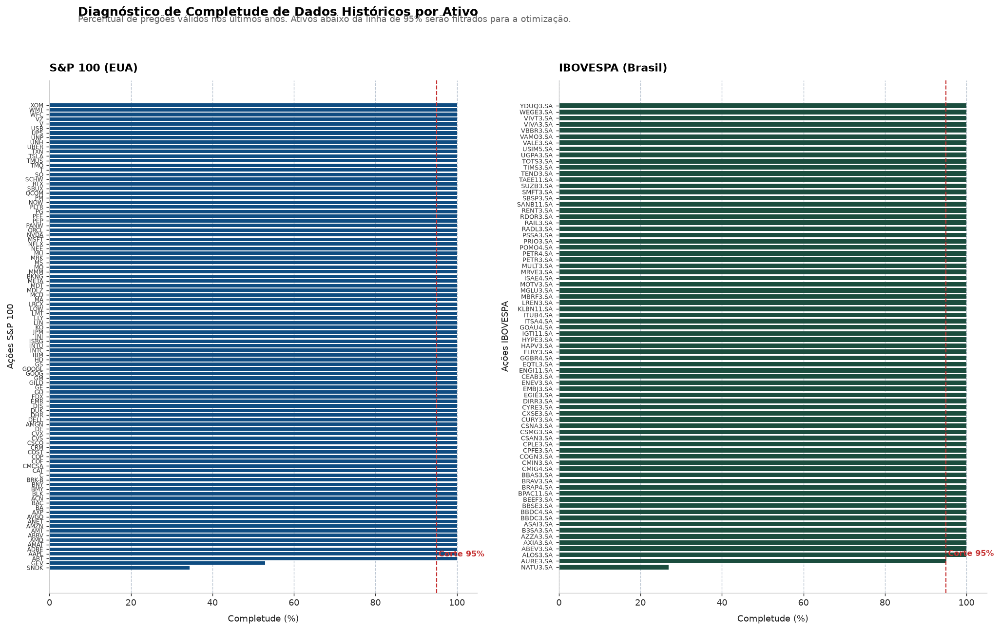

In [11]:
# ==============================================================================
# COMPLETUDE DE DADOS COMPARED: S&P 100 vs IBOVESPA (LADO A LADO)
# ==============================================================================
set_nyt_style()

# 1. Cálculo da completude (%)
completude_sp = (dados_sp100.notnull().mean() * 100).sort_values(ascending=True)
completude_ib = (dados_ibov.notnull().mean() * 100).sort_values(ascending=True)

# 2. Criar subplots lado a lado (1 linha, 2 colunas)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 10), dpi=130)

# ------------------------------------------------------------------------------
# SUBPLOT 1: S&P 100 (Esquerda)
# ------------------------------------------------------------------------------
ax1.barh(completude_sp.index, completude_sp.values, color=CORES['sp100'], height=0.75, zorder=2)
ax1.axvline(x=95, color=CORES['alerta'], linestyle='--', linewidth=1.2, zorder=3)

ax1.set_xlim(0, 105)
ax1.set_xlabel("Completude (%)", fontsize=10, labelpad=8)
ax1.set_ylabel("Ações S&P 100", fontsize=10, labelpad=8)
ax1.set_title('S&P 100 (EUA)', fontsize=12, fontweight='bold', loc='left', pad=10)

ax1.text(95.5, len(completude_sp) * 0.02, 'Corte 95%', color=CORES['alerta'], fontweight='bold', fontsize=9, va='bottom')
ax1.tick_params(axis='y', labelsize=6.5)  # Ajuste fino da fonte dos tickers para caber perfeitamente
ax1.grid(axis='x', color=CORES['neutro'], linestyle='--', alpha=0.7)
ax1.grid(axis='y', visible=False)

# ------------------------------------------------------------------------------
# SUBPLOT 2: IBOVESPA (Direita)
# ------------------------------------------------------------------------------
ax2.barh(completude_ib.index, completude_ib.values, color=CORES['ibov'], height=0.75, zorder=2)
ax2.axvline(x=95, color=CORES['alerta'], linestyle='--', linewidth=1.2, zorder=3)

ax2.set_xlim(0, 105)
ax2.set_xlabel("Completude (%)", fontsize=10, labelpad=8)
ax2.set_ylabel("Ações IBOVESPA", fontsize=10, labelpad=8)
ax2.set_title('IBOVESPA (Brasil)', fontsize=12, fontweight='bold', loc='left', pad=10)

ax2.text(95.5, len(completude_ib) * 0.02, 'Corte 95%', color=CORES['alerta'], fontweight='bold', fontsize=9, va='bottom')
ax2.tick_params(axis='y', labelsize=7)
ax2.grid(axis='x', color=CORES['neutro'], linestyle='--', alpha=0.7)
ax2.grid(axis='y', visible=False)

# ------------------------------------------------------------------------------
# TÍTULOS E AJUSTES EDITORIAIS (NYT STYLE)
# ------------------------------------------------------------------------------
fig.suptitle('Diagnóstico de Completude de Dados Históricos por Ativo', x=0.08, y=0.99, fontweight='bold', fontsize=14, ha='left')
fig.text(
    0.08, 0.965, 
    'Percentual de pregões válidos nos últimos anos. Ativos abaixo da linha de 95% serão filtrados para a otimização.', 
    fontsize=10, color='#666666', ha='left'
)

# Ajuste proporcional de espaçamento entre os subplots
plt.subplots_adjust(top=0.90, wspace=0.25)
plt.tight_layout(rect=[0, 0, 1, 0.95])

# Salvar e exibir sem sobreposição no VS Code
#plt.savefig('missing_sp100_ibov_lado_a_lado.png', dpi=300, bbox_inches='tight')
plt.show()

In [12]:
# ==============================================================================
# ALINHAMENTO DE DATAS E CONVERSÃO SEGURA PARA SERIES
# ==============================================================================
datas_comuns = ret_idx_sp.index.intersection(ret_idx_ib.index)

# Se o seu DataFrame tiver apenas 1 coluna do índice (^OEX e ^BVSP), extraímos como Series:
# (Caso ret_idx_sp tenha 99 colunas, selecione a coluna do benchmark: ret_idx_sp['^OEX'])
s_sp = ret_idx_sp.loc[datas_comuns].squeeze()
s_ib = ret_idx_ib.loc[datas_comuns].squeeze()

# Se por acaso ainda for DataFrame de 1 coluna, forçamos a virar Series:
if isinstance(s_sp, pd.DataFrame):
    s_sp = s_sp.iloc[:, 0]
if isinstance(s_ib, pd.DataFrame):
    s_ib = s_ib.iloc[:, 0]

print(f"✅ Total de pregões comuns analisados: {len(datas_comuns)} dias úteis")
print(f"Período: {datas_comuns[0].strftime('%d/%m/%Y')} a {datas_comuns[-1].strftime('%d/%m/%Y')}\n")

# ==============================================================================
# CÁLCULO DOS RETORNOS ACUMULADOS (BASE 100)
# ==============================================================================
# Para retornos logarítmicos, o acumulado exato é np.exp(cum_sum):
sp_acum = np.exp(s_sp.cumsum()) * 100
ib_acum = np.exp(s_ib.cumsum()) * 100

# ==============================================================================
# TABELA RESUMO COMPARATIVA (COM CONVERSÃO EXPLÍCITA EM FLOAT)
# ==============================================================================
tabela_resumo = pd.DataFrame({
    'S&P 100 (^OEX)': [
        f"{float(s_sp.mean() * 252 * 100):.2f}%",                  # Retorno Anualizado
        f"{float(s_sp.std() * np.sqrt(252) * 100):.2f}%",           # Volatilidade Anualizada
        f"{float(s_sp.mean() / s_sp.std() * np.sqrt(252)):.3f}",    # Sharpe Anualizado
        f"{float(sp_acum.iloc[-1] - 100):.2f}%",                    # Retorno Acumulado Total
        f"{float(s_sp.min() * 100):.2f}%",                          # Pior Dia
        f"{float(s_sp.max() * 100):.2f}%"                           # Melhor Dia
    ],
    'IBOVESPA (^BVSP)': [
        f"{float(s_ib.mean() * 252 * 100):.2f}%",
        f"{float(s_ib.std() * np.sqrt(252) * 100):.2f}%",
        f"{float(s_ib.mean() / s_ib.std() * np.sqrt(252)):.3f}",
        f"{float(ib_acum.iloc[-1] - 100):.2f}%",
        f"{float(s_ib.min() * 100):.2f}%",
        f"{float(s_ib.max() * 100):.2f}%"
    ]
}, index=[
    'Retorno Anualizado', 
    'Volatilidade Anualizada', 
    'Sharpe Anualizado', 
    'Retorno Acumulado Total', 
    'Pior Dia (Retorno Mín.)', 
    'Melhor Dia (Retorno Máx.)'
])

print("=== COMPARATIVO S&P 100 vs. IBOVESPA ===")
print(tabela_resumo.to_string())

✅ Total de pregões comuns analisados: 1153 dias úteis
Período: 04/01/2022 a 01/10/2026

=== COMPARATIVO S&P 100 vs. IBOVESPA ===
                          S&P 100 (^OEX) IBOVESPA (^BVSP)
Retorno Anualizado                15.50%           13.41%
Volatilidade Anualizada           18.02%           17.11%
Sharpe Anualizado                  0.860            0.784
Retorno Acumulado Total          103.25%           84.73%
Pior Dia (Retorno Mín.)           -6.13%           -4.40%
Melhor Dia (Retorno Máx.)          9.71%            5.39%


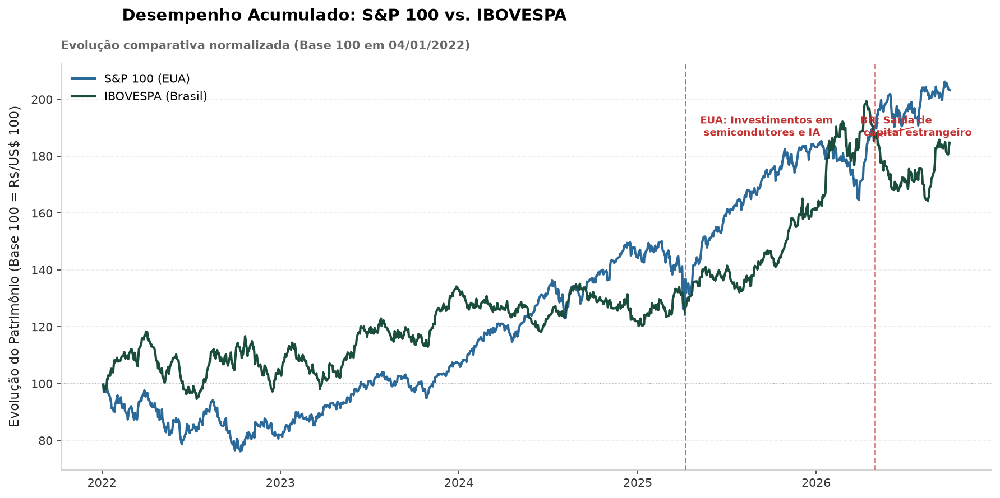

In [13]:
# ==============================================================================
# GRÁFICO COMPARATIVO DE PERFORMANCE ACUMULADA DOS INDICES
# ==============================================================================
# Garante que as configurações visuais do NYT estão ativas
set_nyt_style()

# Criando figura com a interface Orientada a Objetos
fig, ax = plt.subplots(figsize=(12, 6), dpi=150)

# Linha de referência no ponto de partida (Base 100)
ax.axhline(y=100, color='#A0AEC0', linestyle=':', linewidth=1, zorder=1)

# Plot dos índices usando a paleta oficial padronizada do projeto
ax.plot(sp_acum.index, sp_acum, color='#2B6999', linewidth=2, label='S&P 100 (EUA)', zorder=2)
ax.plot(ib_acum.index, ib_acum, color='#1B4D3E', linewidth=2, label='IBOVESPA (Brasil)', zorder=2)

# Grid sutil apenas no eixo Y para não poluir
ax.grid(axis='y', color='#E5E5E5', linestyle='--', alpha=0.7)
ax.grid(axis='x', visible=False)

# Hierarquia do Título (Estilo Manchete Editorial NYT)
plt.suptitle('Desempenho Acumulado: S&P 100 vs. IBOVESPA', x=0.125, y=0.98, fontweight='bold', fontsize=14, ha='left')
ax.set_title(
    f"Evolução comparativa normalizada (Base 100 em {datas_comuns[0].strftime('%d/%m/%Y')})", 
    fontsize=10, color='#666666', pad=12, loc='left'
)

# 6. Marcação de Eventos Históricos de Mercado
data_baixa_B3 = pd.to_datetime('2026-05-01')
data_alta_usa = pd.to_datetime('2025-04-09')

# Linha e anotação: Mínimo no Brasil (Maio 2026)
ax.axvline(data_baixa_B3, color='#C53030', linestyle='--', linewidth=1.2, alpha=0.75, zorder=3)
ax.annotate('BR: Saída de \n capital estrangeiro', xy=(data_baixa_B3, ax.get_ylim()[1] * 0.88), 
            xytext=(data_baixa_B3 - pd.Timedelta(days=30), ax.get_ylim()[1] * 0.88),
            fontsize=8.5, color='#C53030', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='#C53030', lw=0.8))

# Linha e anotação: Início dalta pontual histórica EUA (Mai 2025)
ax.axvline(data_alta_usa, color='#C53030', linestyle='--', linewidth=1.2, alpha=0.75, zorder=3)
ax.annotate('EUA: Investimentos em \n semicondutores e IA', xy=(data_alta_usa, ax.get_ylim()[1] * 0.88), 
            xytext=(data_alta_usa + pd.Timedelta(days=30), ax.get_ylim()[1] * 0.88),
            fontsize=8.5, color='#C53030', fontweight='bold')

# Ajuste dos eixos
ax.set_ylabel('Evolução do Patrimônio (Base 100 = R\\$/US\\$ 100)', fontsize=11, labelpad=8)
ax.set_xlabel('', fontsize=11) # Em séries de tempo, dispensamos a legenda "Data"

# Legenda limpa (sem moldura)
ax.legend(frameon=False, loc='upper left', fontsize=10)

plt.tight_layout()
#plt.savefig('comparativo_acumulado_indices.png', dpi=300, bbox_inches='tight')
plt.show()

IBOVESPA
Total de ações originais: 76
Total de ações mantidas:  75

S&P100
Total de ações originais: 101
Total de ações mantidas:  99

Retornos finais,IBOV: (1128, 75)
Retornos finais,S&P100: (1190, 99)


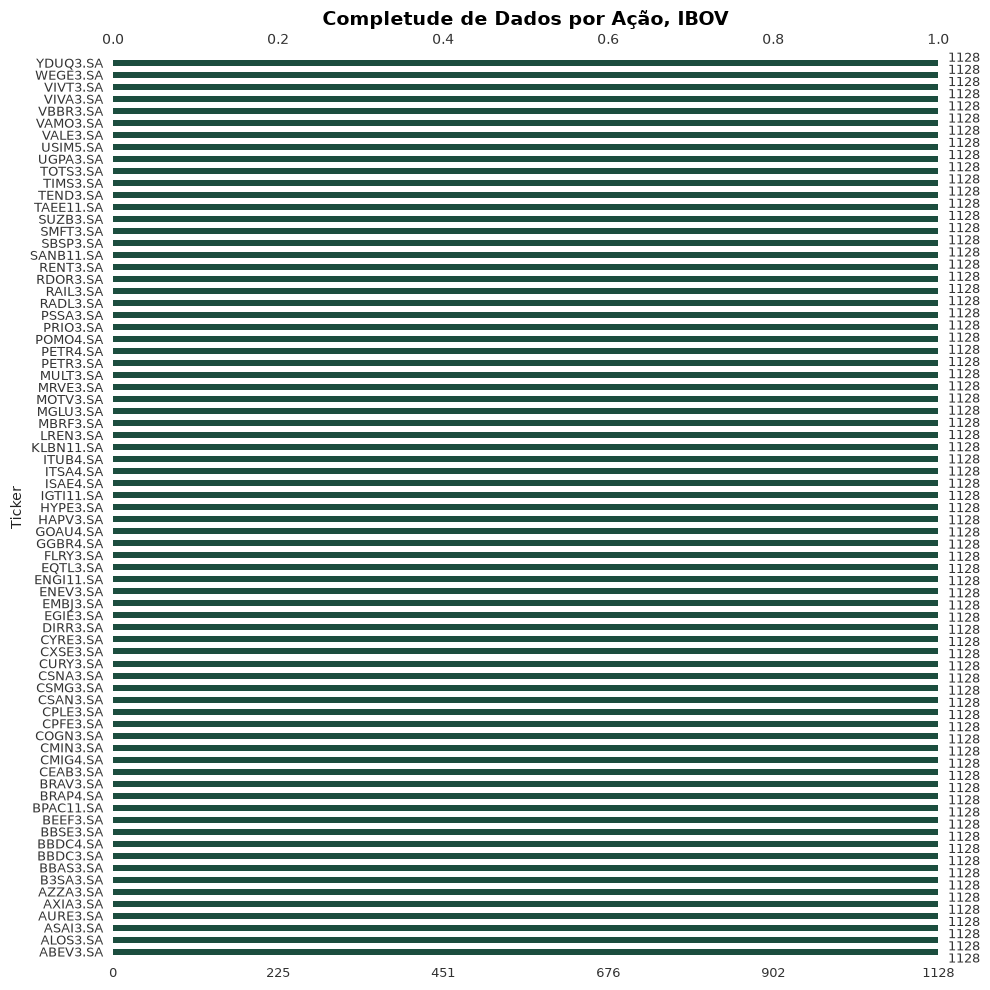

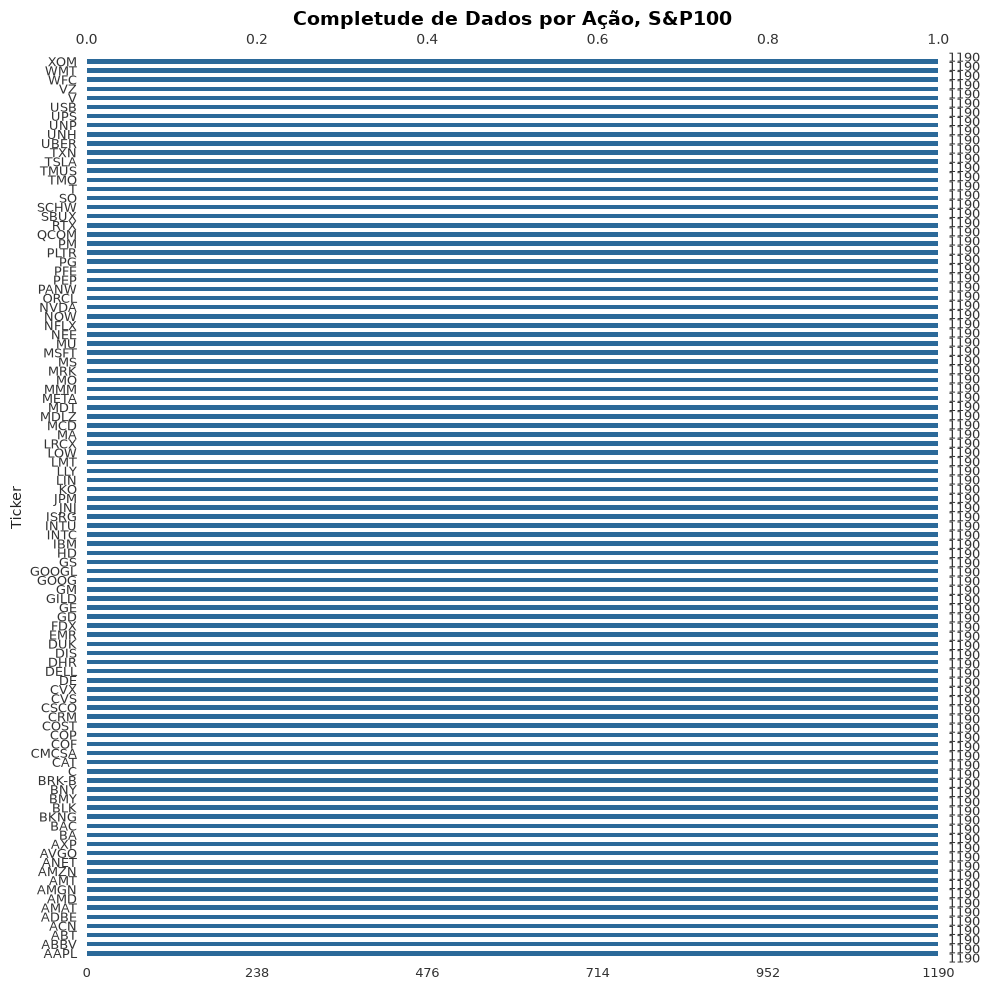

In [14]:
# ══════════════════════════════════════════════════════
# TRATAMENTO DE DADOS FALTANTES
# ══════════════════════════════════════════════════════

# 1. Definir o limite máximo tolerado de NaNs (ex: 5%)
limite_remocao = 5.0

# 2. Calcular a porcentagem de nulos de CADA AÇÃO (por coluna)
pct_nulos_sp100 = dados_sp100.isna().mean() * 100
pct_nulos_ibov = dados_ibov.isna().mean() * 100

# 3. Filtrar as ações que estão DENTRO do limite e extrair os nomes
acoes_validas_sp100 = pct_nulos_sp100[pct_nulos_sp100 <= limite_remocao].index
acoes_validas_ibov = pct_nulos_ibov[pct_nulos_ibov <= limite_remocao].index

#Criando o novo DataFrame filtrado contendo apenas as ações válidas
dados_sp100_clean = dados_sp100[acoes_validas_sp100]
dados_ibov_clean = dados_ibov[acoes_validas_ibov]

# 4 Preencher dados faltantes (<5%) restantes com forward fill
dados_sp100_clean = dados_sp100_clean.ffill() # ffill preenche com o último valor disponível
dados_ibov_clean = dados_ibov_clean.ffill()

# 5. Criar o novo DataFrame filtrado contendo apenas as ações válidas
dados_sp100_clean = dados_sp100[acoes_validas_sp100]
dados_ibov_clean = dados_ibov[acoes_validas_ibov]
print ("IBOVESPA")
print(f"Total de ações originais: {dados_ibov.shape[1]}")
print(f"Total de ações mantidas:  {len(acoes_validas_ibov)}")

print ("\nS&P100")
print(f"Total de ações originais: {dados_sp100.shape[1]}")
print(f"Total de ações mantidas:  {len(acoes_validas_sp100)}")

# 6. Verificar se ainda há nulos (linhas iniciais podem ter NaN)
dados_sp100_clean = dados_sp100_clean.dropna(how='all')
dados_ibov_clean = dados_ibov_clean.dropna(how='all')

# Recalcular retornos com dados limpos
ret_sp100_clean = np.log(dados_sp100_clean / dados_sp100_clean.shift(1)).dropna()
ret_ibov_clean = np.log(dados_ibov_clean / dados_ibov_clean.shift(1)).dropna()
print(f'\nRetornos finais,IBOV: {ret_ibov_clean.shape}')
print(f'Retornos finais,S&P100: {ret_sp100_clean.shape}')

# Visualização, mapa de calor de dados completos após limpeza
fig, ax = plt.subplots(figsize=(10, 10))
msno.bar(ret_ibov_clean, ax=ax, color='#1B4D3E', fontsize=9)
ax.set_title('Completude de Dados por Ação, IBOV', fontweight='bold')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 10))
msno.bar(ret_sp100_clean, ax=ax, color='#2B6999', fontsize=9)
ax.set_title('Completude de Dados por Ação, S&P100', fontweight='bold')
plt.tight_layout()
plt.show()

# Salvar os retornos com os dados limpos
ret_sp100_clean.to_csv('sp100_retornos_limpos.csv')
ret_ibov.to_csv('ibov_retornos_limpos.csv')

In [15]:
# ══════════════════════════════════════════════════════
#Identificação de Outliers nos Retornos
# ══════════════════════════════════════════════════════

# Detectar retornos extremos por ação
limite_outlier = 0.15 # ±15% em um dia,ajuste conforme necessário
outliers_sp = (ret_sp100_clean.abs() > limite_outlier).sum()
print('Ações com retornos diários > 15% (S&P100):')
print(outliers_sp[outliers_sp > 0].sort_values(ascending=False).head(15))

outliers_ibov = (ret_ibov_clean.abs() > limite_outlier).sum()
print('\nAções com retornos diários > 15% (IBOV):')
print(outliers_ibov[outliers_ibov > 0].sort_values(ascending=False).head(15))

# ══════════════════════════════════════════════════════
#Aqui Investiga uma ação específica suspeita
# ══════════════════════════════════════════════════════
acao_suspeita = 'TSLA' # Substituir por qualquer ação do S&P100 ou IBOVESPA que você queira investigar
if acao_suspeita in ret_sp100_clean.columns:
    retornos_acao = ret_sp100_clean[acao_suspeita]
    dias_extremos = retornos_acao[retornos_acao.abs() > limite_outlier]
    print(f'\nDias com retorno extremo,{acao_suspeita}:')
    formato = len(dias_extremos)
    print(dias_extremos.sort_values(key=abs, ascending=False))
    print(f'Quantidade de dias extremos: {formato}')

Ações com retornos diários > 15% (S&P100):
Ticker
PLTR    12
DELL     7
MU       5
META     5
INTC     5
TSLA     5
NVDA     4
AMD      4
ANET     4
UNH      3
AVGO     3
SBUX     2
NFLX     2
FDX      2
ISRG     2
dtype: int64

Ações com retornos diários > 15% (IBOV):
Ticker
TEND3.SA    8
HAPV3.SA    8
CEAB3.SA    7
MGLU3.SA    5
YDUQ3.SA    3
BBDC4.SA    2
BRAV3.SA    2
CSNA3.SA    2
MBRF3.SA    2
RADL3.SA    2
CPLE3.SA    1
BBDC3.SA    1
AXIA3.SA    1
BEEF3.SA    1
AZZA3.SA    1
dtype: int64

Dias com retorno extremo,TSLA:
Date
2025-04-09    0.204491
2024-10-24    0.198187
2025-03-10   -0.167546
2026-07-23   -0.156931
2025-06-05   -0.153849
Name: TSLA, dtype: float64
Quantidade de dias extremos: 5


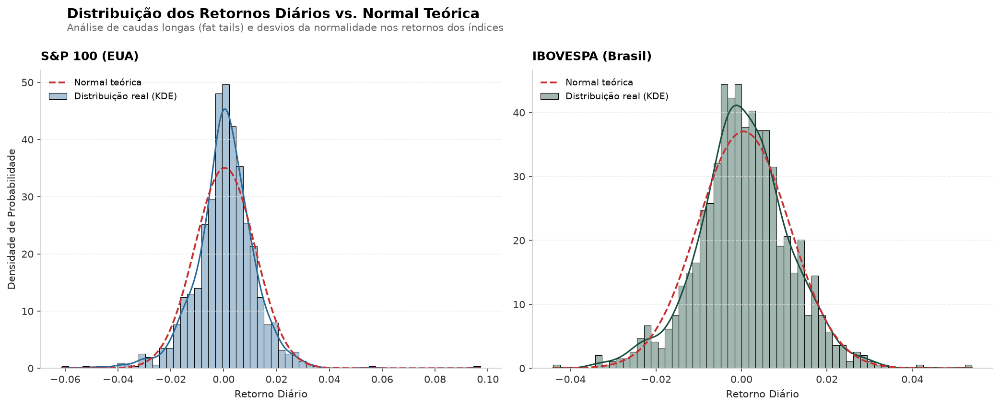

      ANÁLISE ESTATÍSTICA DE RISCO E DISTRIBUIÇÃO

--- ASSIMETRIA (SKEWNESS) ---
S&P 100:  0.08  (Normal = 0)
IBOVESPA: -0.02  (Normal = 0)

--- CURTOSE EM EXCESSO (KURTOSIS) ---
S&P 100:  6.36  (Normal = 0)
IBOVESPA: 1.12  (Normal = 0)

🔍 INTERPRETAÇÃO DOS RESULTADOS:
• Curtose > 0 (Fat Tails): Ambos os índices apresentam caudas gordas.
  Eventos extremos (choques e crises) ocorrem com frequência superior à prevista pela distribuição Normal.
• Assimetria > 0: Distribuição levemente inclinada
O valor de referência é 0,00, indicando uma curva perfeitamente simétrica onde ganhos e perdas têm distribuição espelhada


In [16]:
# ==============================================================================
# GRÁFICO DE DISTRIBUIÇÃO DE RETORNOS VS. CURVA NORMAL 
# ==============================================================================
set_nyt_style()

# Extração segura dos valores numéricos para cálculo estatístico
s_sp_vals = ret_idx_sp["^OEX"].dropna()
s_ib_vals = ret_idx_ib["^BVSP"].dropna()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=150)

# ------------------------------------------------------------------------------
# PAINEL 1: S&P 100 (EUA)
# ------------------------------------------------------------------------------
# Histograma e KDE real normalizados por densidade
sns.histplot(s_sp_vals, bins=60, stat="density", kde=True, 
             color='#2B6999', alpha=0.4, ax=ax1, label='Distribuição real (KDE)')

# Cálculo da Curva Normal Teórica
mu_sp, sigma_sp = s_sp_vals.mean(), s_sp_vals.std()
x_sp = np.linspace(s_sp_vals.min(), s_sp_vals.max(), 200)
pdf_sp = (1 / (sigma_sp * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x_sp - mu_sp) / sigma_sp) ** 2)

ax1.plot(x_sp, pdf_sp, color=CORES['alerta'], linestyle='--', linewidth=1.8, label='Normal teórica')

# Ajustes estéticos - Painel 1
ax1.set_title('S&P 100 (EUA)', fontsize=12, fontweight='bold', loc='left', pad=10)
ax1.set_xlabel('Retorno Diário', fontsize=10)
ax1.set_ylabel('Densidade de Probabilidade', fontsize=10)
ax1.grid(axis='y', color='#E5E5E5', linestyle='--', alpha=0.7)
ax1.grid(axis='x', visible=False)
ax1.legend(frameon=False, loc='upper left', fontsize=9)

# ------------------------------------------------------------------------------
# PAINEL 2: IBOVESPA (Brasil)
# ------------------------------------------------------------------------------
# Histograma e KDE real normalizados por densidade
sns.histplot(s_ib_vals, bins=60, stat="density", kde=True, 
             color='#1B4D3E', alpha=0.4, ax=ax2, label='Distribuição real (KDE)')

# Cálculo da Curva Normal Teórica
mu_ib, sigma_ib = s_ib_vals.mean(), s_ib_vals.std()
x_ib = np.linspace(s_ib_vals.min(), s_ib_vals.max(), 200)
pdf_ib = (1 / (sigma_ib * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x_ib - mu_ib) / sigma_ib) ** 2)

ax2.plot(x_ib, pdf_ib, color=CORES['alerta'], linestyle='--', linewidth=1.8, label='Normal teórica')

# Ajustes estéticos - Painel 2
ax2.set_title('IBOVESPA (Brasil)', fontsize=12, fontweight='bold', loc='left', pad=10)
ax2.set_xlabel('Retorno Diário', fontsize=10)
ax2.set_ylabel('', fontsize=10) # Remove rótulo duplicado no segundo painel
ax2.grid(axis='y', color='#E5E5E5', linestyle='--', alpha=0.7)
ax2.grid(axis='x', visible=False)
ax2.legend(frameon=False, loc='upper left', fontsize=9)

# ------------------------------------------------------------------------------
# TÍTULO GERAL E CONFIGURAÇÕES FINAIS
# ------------------------------------------------------------------------------
plt.suptitle('Distribuição dos Retornos Diários vs. Normal Teórica', x=0.07, y=1.02, fontweight='bold', fontsize=14, ha='left')
fig.text(0.07, 0.96, 'Análise de caudas longas (fat tails) e desvios da normalidade nos retornos dos índices', fontsize=10, color='#666666')

plt.tight_layout()
#plt.savefig('distribuicao_retornos.png', dpi=300, bbox_inches='tight')
plt.show()

# ==============================================================================
# CÁLCULO E EXIBIÇÃO DA ASSIMETRIA E CURTOSE
# ==============================================================================
skew_sp = s_sp_vals.skew()
skew_ib = s_ib_vals.skew()

kurt_sp = s_sp_vals.kurtosis()
kurt_ib = s_ib_vals.kurtosis()

print("=" * 55)
print("      ANÁLISE ESTATÍSTICA DE RISCO E DISTRIBUIÇÃO")
print("=" * 55)
print("\n--- ASSIMETRIA (SKEWNESS) ---")
print(f"S&P 100:  {skew_sp:.2f}  (Normal = 0)")
print(f"IBOVESPA: {skew_ib:.2f}  (Normal = 0)")

print("\n--- CURTOSE EM EXCESSO (KURTOSIS) ---")
print(f"S&P 100:  {kurt_sp:.2f}  (Normal = 0)")
print(f"IBOVESPA: {kurt_ib:.2f}  (Normal = 0)")
print("=" * 55)

# INTERPRETAÇÃO FINANCEIRA
print("\n🔍 INTERPRETAÇÃO DOS RESULTADOS:")
print("• Curtose > 0 (Fat Tails): Ambos os índices apresentam caudas gordas.")
print("  Eventos extremos (choques e crises) ocorrem com frequência superior à prevista pela distribuição Normal.")
print("• Assimetria > 0: Distribuição levemente inclinada")
print("O valor de referência é 0,00, indicando uma curva perfeitamente simétrica onde ganhos e perdas têm distribuição espelhada")

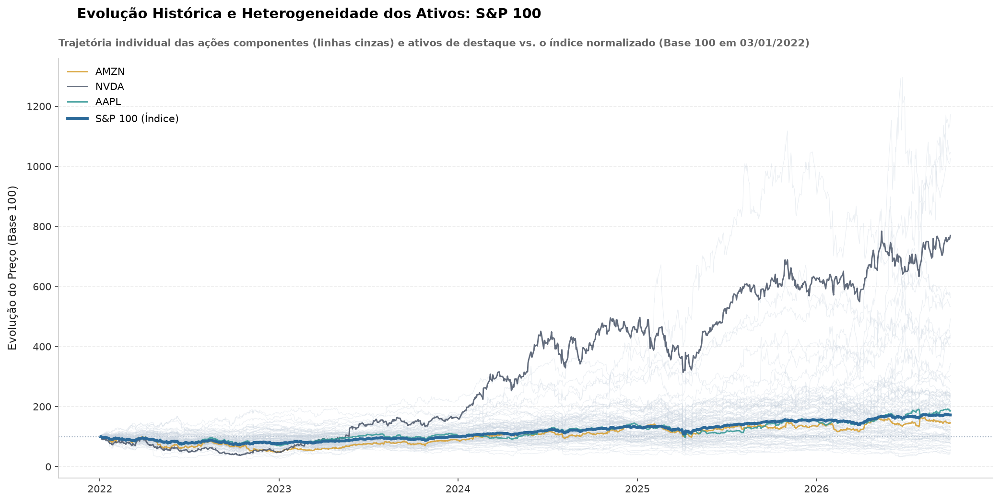

In [17]:
# ==============================================================================
# PERFORMANCE NORMALIZADA S&P 100
# ==============================================================================
set_nyt_style()

# 1. Cálculo da performance normalizada (Base 100 no início)
precos_norm_sp = (dados_sp100_clean / dados_sp100_clean.iloc[0] * 100)
indice_norm_sp = (indice_sp100 / indice_sp100.iloc[0] * 100)

fig, ax = plt.subplots(figsize=(14, 7), dpi=150)

# 2. Linha de referência na Base 100
ax.axhline(y=100, color='#A0AEC0', linestyle=':', linewidth=1, zorder=1)

# 3. Ações individuais em cinza sutil ao fundo ("Feixe de luz")
for col in precos_norm_sp.columns:
    ax.plot(precos_norm_sp.index, precos_norm_sp[col], color='#CBD5E0', linewidth=0.6, alpha=0.35, zorder=2)

# 4. Destacar ações chave em tons sóbrios
destaques = {
    'AMZN': '#D69E2E',  # Dourado/Amber para alto crescimento
    'NVDA': '#4A5568',  # Cinza Escuro Slate
    'AAPL': '#319795',  # Teal/Azul-Verde
}

for acao, cor in destaques.items():
    if acao in precos_norm_sp.columns:
        ax.plot(precos_norm_sp.index, precos_norm_sp[acao], color=cor, linewidth=1.4, alpha=0.85, label=acao, zorder=3)

# 5. Índice S&P 100 em Destaque Principal (Azul Oficial do Projeto)
ax.plot(indice_norm_sp.index, indice_norm_sp, color='#2B6999', linewidth=2.8, label='S&P 100 (Índice)', zorder=4)


# 7. Ajustes Estéticos e Grid
ax.set_yscale('linear') # Mantenha 'log' se o pico da NVDA for excessivo e achatar as outras
ax.set_ylabel('Evolução do Preço (Base 100)', fontsize=11, labelpad=8)
ax.set_xlabel('', fontsize=11)
ax.grid(axis='y', color='#E5E5E5', linestyle='--', alpha=0.7)
ax.grid(axis='x', visible=False)

# Legenda Limpa
ax.legend(frameon=False, loc='upper left', fontsize=10)

# 8. Títulos no estilo NYT (Corrigido tecnicamente)
plt.suptitle('Evolução Histórica e Heterogeneidade dos Ativos: S&P 100', x=0.08, y=0.99, fontweight='bold', fontsize=14, ha='left')
ax.set_title(
    f"Trajetória individual das ações componentes (linhas cinzas) e ativos de destaque vs. o índice normalizado (Base 100 em {precos_norm_sp.index[0].strftime('%d/%m/%Y')})", 
    fontsize=10, color='#666666', pad=12, loc='left'
)

plt.tight_layout()
#plt.savefig('performance_normalizada_sp100.png', dpi=300, bbox_inches='tight')
plt.show()

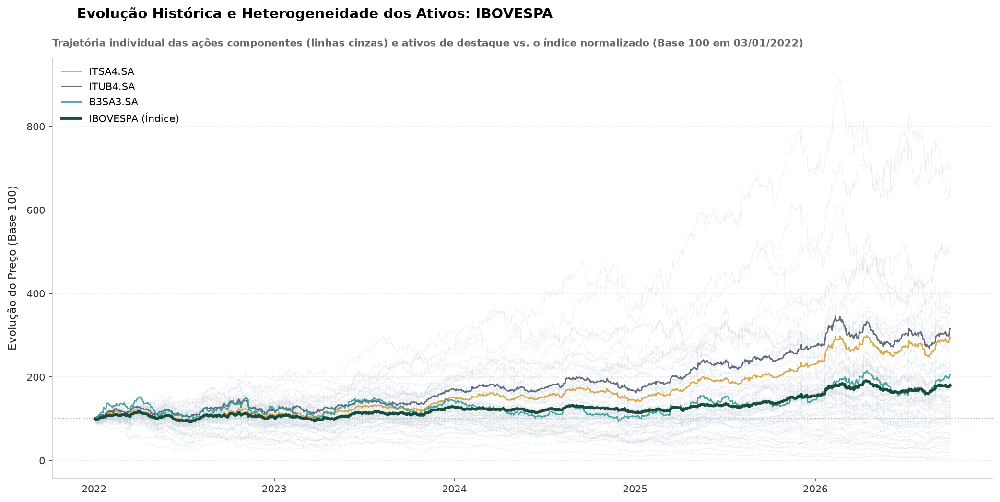

In [18]:
# ══════════════════════════════════════════════════════
# Performance Normalizada IBOVESPA
# ══════════════════════════════════════════════════════
set_nyt_style()

# 1. Cálculo da performance normalizada (Base 100 no início)
precos_norm_ib = (dados_ibov_clean / dados_ibov_clean.iloc[0] * 100)
indice_norm_ib = (indice_ibov / indice_ibov.iloc[0] * 100)

fig, ax = plt.subplots(figsize=(14, 7), dpi=150)

# 2. Linha de referência na Base 100
ax.axhline(y=100, color='#A0AEC0', linestyle=':', linewidth=1, zorder=1)

# 3. Ações individuais em cinza sutil ao fundo ("Feixe de luz")
for col in precos_norm_ib.columns:
    ax.plot(precos_norm_ib.index, precos_norm_ib[col], color='#CBD5E0', linewidth=0.6, alpha=0.35, zorder=2)

# 4. Destacar ações chave em tons sóbrios
destaques = {
    'ITSA4.SA': '#D69E2E',  # Dourado/Amber para alto crescimento
    'ITUB4.SA': '#4A5568',  # Cinza Escuro Slate
    'B3SA3.SA': '#319795',  # Teal/Azul-Verde
}




for acao, cor in destaques.items():
    if acao in precos_norm_ib.columns:
        ax.plot(precos_norm_ib.index, precos_norm_ib[acao], color=cor, linewidth=1.4, alpha=0.85, label=acao, zorder=3)

# 5. Índice IBOVESPA em Destaque Principal (Verde Oficial do Projeto)
ax.plot(indice_norm_ib.index, indice_norm_ib, color=CORES['ibov'], linewidth=2.8, label='IBOVESPA (Índice)', zorder=4)


# 7. Ajustes Estéticos e Grid
ax.set_yscale('linear') # Mantenha 'log' se o pico da NVDA for excessivo e achatar as outras
ax.set_ylabel('Evolução do Preço (Base 100)', fontsize=11, labelpad=8)
ax.set_xlabel('', fontsize=11)
ax.grid(axis='y', color='#E5E5E5', linestyle='--', alpha=0.7)
ax.grid(axis='x', visible=False)

# Legenda Limpa
ax.legend(frameon=False, loc='upper left', fontsize=10)

# 8. Títulos no estilo NYT (Corrigido tecnicamente)
plt.suptitle('Evolução Histórica e Heterogeneidade dos Ativos: IBOVESPA', x=0.08, y=0.99, fontweight='bold', fontsize=14, ha='left')
ax.set_title(
    f"Trajetória individual das ações componentes (linhas cinzas) e ativos de destaque vs. o índice normalizado (Base 100 em {precos_norm_sp.index[0].strftime('%d/%m/%Y')})", 
    fontsize=10, color='#666666', pad=12, loc='left'
)

plt.tight_layout()
#plt.savefig('performance_normalizada_ibovespa.png', dpi=300, bbox_inches='tight')
plt.show()

TOP 15, Ações mais correlacionadas com o S&P100:
Ticker
NVDA     0.7484
AMZN     0.7423
AAPL     0.7420
MSFT     0.7302
BLK      0.7175
GOOG     0.7062
GOOGL    0.7046
LRCX     0.6674
MS       0.6656
GS       0.6613
AVGO     0.6587
AMD      0.6586
AXP      0.6548
AMAT     0.6520
QCOM     0.6434
dtype: float64

BOTTOM 10, Ações menos correlacionadas com o S&P100:
Ticker
MRK    0.1769
PM     0.1733
BMY    0.1710
SO     0.1645
T      0.1453
DUK    0.1328
VZ     0.1318
JNJ    0.1245
LMT    0.1188
MO     0.0885
dtype: float64


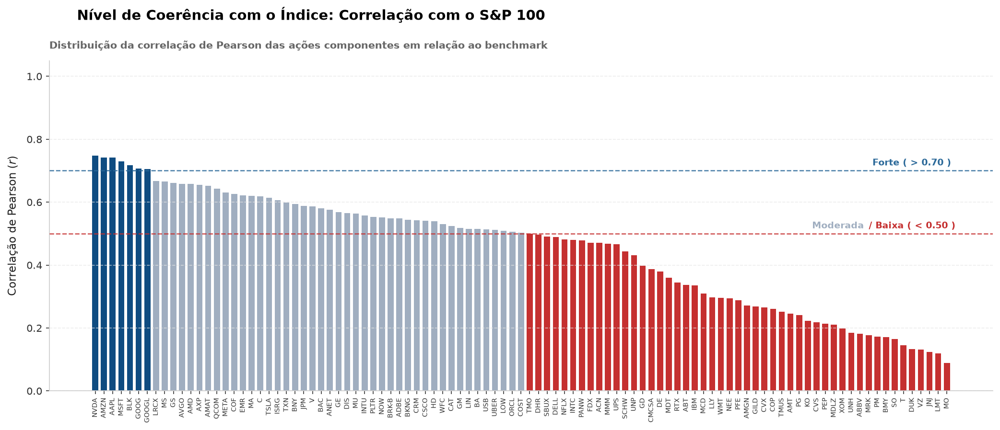


7.1% das ações têm correlação > 0.7 com o índice


In [19]:
# ══════════════════════════════════════════════════════
# Correlação de cada ação com o Índice (S&P100)
# ══════════════════════════════════════════════════════
# Alinhar os índices de data primeiro para garantir a comparação correta
datas_comuns_sp = ret_sp100_clean.index.intersection(ret_idx_sp.index)
ret_acoes_sp_al = ret_sp100_clean.loc[datas_comuns_sp]
ret_idx_sp_al = ret_idx_sp.loc[datas_comuns_sp]

# Calcular correlação utilizando .squeeze() para transformar o índice em Series (1D)
corr_com_idx_sp = ret_acoes_sp_al.corrwith(ret_idx_sp_al.squeeze()).sort_values(ascending=False)

print('TOP 15, Ações mais correlacionadas com o S&P100:')
print(corr_com_idx_sp.head(15).round(4))
print('\nBOTTOM 10, Ações menos correlacionadas com o S&P100:')
print(corr_com_idx_sp.tail(10).round(4))

# ==============================================================================
# GRÁFICO DE CORRELAÇÃO DAS AÇÕES COM O S&P 100 (ESTILO NYT)
# ==============================================================================
set_nyt_style()

# Garante que temos as ações e os valores ordenados para melhor leitura visual
corr_ordenada = corr_com_idx_sp.sort_values(ascending=False)
acoes = corr_ordenada.index
valores = corr_ordenada.values

# Mapeamento de Cores no Padrão do Projeto
# Alta (>0.7): Azul S&P | Moderada (0.5 a 0.7): Slate/Cinza | Baixa (<0.5): Carmesim/Alerta
cores = [
    '#0F4C81' if c > 0.7 else ('#A0AEC0' if c >= 0.5 else '#C53030') 
    for c in valores
]

fig, ax = plt.subplots(figsize=(14, 6), dpi=150)

# Criando as barras verticais
ax.bar(acoes, valores, color=cores, width=0.7, edgecolor='none')

# Linhas horizontais de referência pontilhadas
ax.axhline(0.70, color='#2B6999', linestyle='--', linewidth=1.2, alpha=0.85, zorder=3)
ax.axhline(0.50, color='#C53030', linestyle='--', linewidth=1.2, alpha=0.85, zorder=3)

# Anotações diretas nas linhas (descarta a legenda tradicional)
ax.text(len(acoes_validas_sp100) - 0.5, 0.71, 'Forte ( > 0.70 )', color='#2B6999', fontweight='bold', fontsize=9, ha='right', va='bottom')
ax.text(len(acoes_validas_sp100) - 9, 0.51, 'Moderada    ', color='#A0AEC0', fontweight='bold', fontsize=9, ha='right', va='bottom')
ax.text(len(acoes_validas_sp100) - 0, 0.51, '/ Baixa ( < 0.50 )', color='#C53030', fontweight='bold', fontsize=9, ha='right', va='bottom')


# Ajuste e formatação dos Eixos
ax.set_ylim(0, 1.05)
ax.set_ylabel('Correlação de Pearson ($r$)', fontsize=11, labelpad=8)
ax.set_xlabel('', fontsize=11)

# Rotação dos tickers das ações no eixo X
plt.xticks(rotation=90, fontsize=6.5)

# Grid sutil apenas no eixo Y
ax.grid(axis='y', color='#E5E5E5', linestyle='--', alpha=0.7)
ax.grid(axis='x', visible=False)

# Títulos no estilo editorial NYT
plt.suptitle('Nível de Coerência com o Índice: Correlação com o S&P 100', x=0.08, y=0.99, fontweight='bold', fontsize=14, ha='left')
ax.set_title(
    'Distribuição da correlação de Pearson das ações componentes em relação ao benchmark', 
    fontsize=10, color='#666666', pad=12, loc='left'
)

plt.tight_layout()
#plt.savefig('correlacao_acoes_sp100.png', dpi=300, bbox_inches='tight')
plt.show()

# Calcular a porcentagem de ações com alta correlação
pct_alta_corr = (corr_com_idx_sp > 0.7).mean() * 100
print(f'\n{pct_alta_corr:.1f}% das ações têm correlação > 0.7 com o índice')

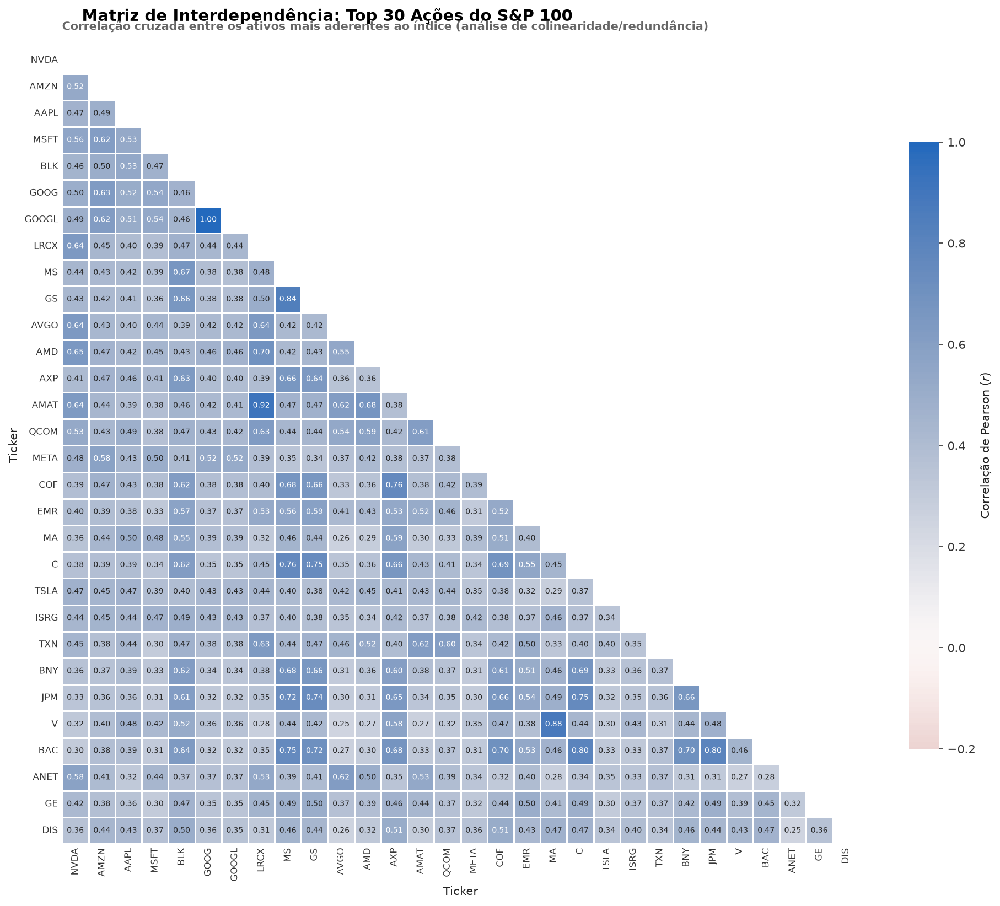

   PARES COM CORRELAÇÃO EXTREMA (> 0.90) — S&P 100
Total de pares altamente redundantes encontrados: 2

Ação 1 Ação 2  Correlação
  GOOG  GOOGL       0.997
  AMAT   LRCX       0.917


In [20]:
# ==============================================================================
# MATRIZ DE CORRELAÇÃO TOP 30 S&P 100 (ESTILO NYT)
# ==============================================================================
set_nyt_style()

# 1. Matriz de correlação geral e seleção das 30 principais ações
corr_matrix_sp = ret_sp100_clean.corr()
top30_sp = corr_com_idx_sp.head(30).index
corr_top30_sp = ret_sp100[top30_sp].corr()

# 2. Criar figura no padrão Orientado a Objetos
fig, ax = plt.subplots(figsize=(13, 11), dpi=150)

# 3. Criar máscara para o triângulo superior (exibe apenas o triângulo inferior)
mask = np.triu(np.ones_like(corr_top30_sp, dtype=bool))

# 4. Plotar Heatmap com paleta sóbria e linhas sutis
sns.heatmap(
    corr_top30_sp,
    mask=mask,
    annot=True, 
    fmt='.2f',
    cmap='vlag_r',        # Paleta divergente sutil (Azul vs Vermelho fechado)
    center=0, 
    square=True,
    linewidths=0.5,
    linecolor='#FFFFFF',  # Linhas separadoras brancas limpas
    vmin=-0.2, vmax=1,    # Ajuste de escala focado na faixa real de correlação de ações
    cbar_kws={
        'shrink': 0.75, 
        'label': 'Correlação de Pearson ($r$)',
        'orientation': 'vertical'
    },
    annot_kws={'size': 6.5, 'weight': 'normal'},
    ax=ax
)

# 5. Ajuste nos eixos para eliminar bordas de tick
ax.tick_params(axis='both', which='both', length=0, labelsize=8)
plt.xticks(rotation=90)
plt.yticks(rotation=0)

# 6. Títulos no estilo editorial NYT
plt.suptitle(
    'Matriz de Interdependência: Top 30 Ações do S&P 100', 
    x=0.08, y=0.98, fontweight='bold', fontsize=14, ha='left'
)
ax.set_title(
    'Correlação cruzada entre os ativos mais aderentes ao índice (análise de colinearidade/redundância)', 
    fontsize=10, color='#666666', pad=15, loc='left'
)

plt.tight_layout()
#plt.savefig('matriz_correlacao_sp100.png', dpi=300, bbox_inches='tight')
plt.show()

# ==============================================================================
# BUSCA DE PARES DE ALTA CORRELAÇÃO (REDUNDÂNCIA PARA O SOLVER)
# ==============================================================================
pares_alta_corr = []
for i in range(len(corr_matrix_sp.columns)):
    for j in range(i + 1, len(corr_matrix_sp.columns)):
        r = corr_matrix_sp.iloc[i, j]
        if r > 0.90:
            pares_alta_corr.append({
                'Ação 1': corr_matrix_sp.columns[i],
                'Ação 2': corr_matrix_sp.columns[j],
                'Correlação': round(r, 3)
            })

df_pares = pd.DataFrame(pares_alta_corr).sort_values('Correlação', ascending=False)

print("=" * 60)
print(f"   PARES COM CORRELAÇÃO EXTREMA (> 0.90) — S&P 100")
print("=" * 60)
print(f"Total de pares altamente redundantes encontrados: {len(df_pares)}\n")
if len(df_pares) > 0:
    print(df_pares.head(20).to_string(index=False))
print("=" * 60)

TOP 15, Ações mais correlacionadas com o IBOVESPA:
Ticker
ITSA4.SA     0.7981
ITUB4.SA     0.7581
BPAC11.SA    0.7389
B3SA3.SA     0.7311
ALOS3.SA     0.7214
BBDC3.SA     0.6994
IGTI11.SA    0.6921
MULT3.SA     0.6852
MOTV3.SA     0.6820
CSAN3.SA     0.6779
BBDC4.SA     0.6698
RENT3.SA     0.6676
SANB11.SA    0.6464
CYRE3.SA     0.6455
VBBR3.SA     0.6391
dtype: float64

BOTTOM 10, Ações menos correlacionadas com o IBOVESPA:
Ticker
WEGE3.SA     0.4027
POMO4.SA     0.4008
BRAV3.SA     0.3921
KLBN11.SA    0.3886
BBSE3.SA     0.3869
PRIO3.SA     0.3653
BEEF3.SA     0.3483
MBRF3.SA     0.3328
EMBJ3.SA     0.2796
SUZB3.SA     0.2211
dtype: float64


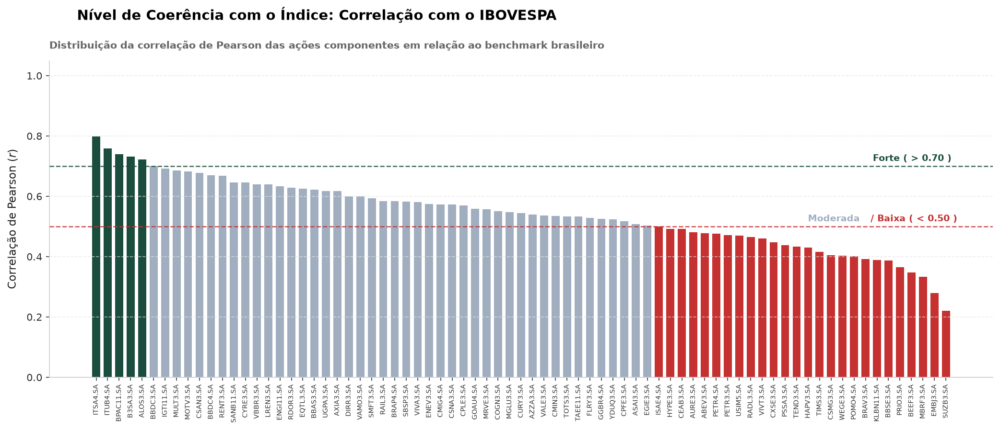


6.7% das ações têm correlação > 0.7 com o índice


In [21]:
# ══════════════════════════════════════════════════════
# Correlação de cada ação com o Índice (IBOVESPA)
# ══════════════════════════════════════════════════════
# Alinhar os índices de data primeiro para garantir a comparação correta
datas_comuns_ib = ret_ibov_clean.index.intersection(ret_idx_ib.index)
ret_acoes_ib_al = ret_ibov_clean.loc[datas_comuns_ib]
ret_idx_ib_al = ret_idx_ib.loc[datas_comuns_ib]

# Calcular correlação utilizando .squeeze() para transformar o índice em Series (1D)
corr_com_idx_ib = ret_acoes_ib_al.corrwith(ret_idx_ib_al.squeeze()).sort_values(ascending=False)

print('TOP 15, Ações mais correlacionadas com o IBOVESPA:')
print(corr_com_idx_ib.head(15).round(4))
print('\nBOTTOM 10, Ações menos correlacionadas com o IBOVESPA:')
print(corr_com_idx_ib.tail(10).round(4))

# ==============================================================================
# GRÁFICO DE CORRELAÇÃO DAS AÇÕES COM O IBOVESPA (ESTILO NYT)
# ==============================================================================
set_nyt_style()

# 1. Ordenação decrescente dos dados para melhor leitura visual
corr_ordenada_ib = corr_com_idx_ib.sort_values(ascending=False)
acoes_ib = corr_ordenada_ib.index
valores_ib = corr_ordenada_ib.values

# 2. Mapeamento de Cores no Padrão do Projeto
# Alta (>0.7): Verde IBOV | Moderada (0.5 a 0.7): Slate/Cinza | Baixa (<0.5): Carmesim/Alerta
cores_ib = [
    '#1B4D3E' if c > 0.7 else ('#A0AEC0' if c >= 0.5 else '#C53030') 
    for c in valores_ib
]

fig, ax = plt.subplots(figsize=(14, 6), dpi=150)

# 3. Criando as barras verticais
ax.bar(acoes_ib, valores_ib, color=cores_ib, width=0.7, edgecolor='none')

# 4. Linhas horizontais de referência pontilhadas
ax.axhline(0.70, color='#1B4D3E', linestyle='--', linewidth=1.2, alpha=0.85, zorder=3)
ax.axhline(0.50, color='#C53030', linestyle='--', linewidth=1.2, alpha=0.85, zorder=3)

# 5. Anotações diretas nas linhas (sem poluição de legenda)
ax.text(len(acoes_validas_ibov) - 0.5, 0.71, 'Forte ( > 0.70 )', color='#1B4D3E', fontweight='bold', fontsize=9, ha='right', va='bottom')
ax.text(len(acoes_validas_ibov) - 8.5, 0.51, 'Moderada', color='#A0AEC0', fontweight='bold', fontsize=9, ha='right', va='bottom')
ax.text(len(acoes_validas_ibov) - 0, 0.51, '/ Baixa ( < 0.50 )', color='#C53030', fontweight='bold', fontsize=9, ha='right', va='bottom')


# 6. Ajuste e formatação dos Eixos
ax.set_ylim(0, 1.05)
ax.set_ylabel('Correlação de Pearson ($r$)', fontsize=11, labelpad=8)
ax.set_xlabel('', fontsize=11)

# Rotação dos tickers das ações no eixo X
plt.xticks(rotation=90, fontsize=6.5)

# Grid sutil apenas no eixo Y
ax.grid(axis='y', color='#E5E5E5', linestyle='--', alpha=0.7)
ax.grid(axis='x', visible=False)

# 7. Títulos no estilo editorial NYT
plt.suptitle('Nível de Coerência com o Índice: Correlação com o IBOVESPA', x=0.08, y=0.99, fontweight='bold', fontsize=14, ha='left')
ax.set_title(
    'Distribuição da correlação de Pearson das ações componentes em relação ao benchmark brasileiro', 
    fontsize=10, color='#666666', pad=12, loc='left'
)

plt.tight_layout()
#plt.savefig('correlacao_acoes_ibovespa.png', dpi=300, bbox_inches='tight')
plt.show()

# Calcular a porcentagem de ações com alta correlação
pct_alta_corr_ib = (corr_com_idx_ib > 0.7).mean() * 100
print(f'\n{pct_alta_corr_ib:.1f}% das ações têm correlação > 0.7 com o índice')

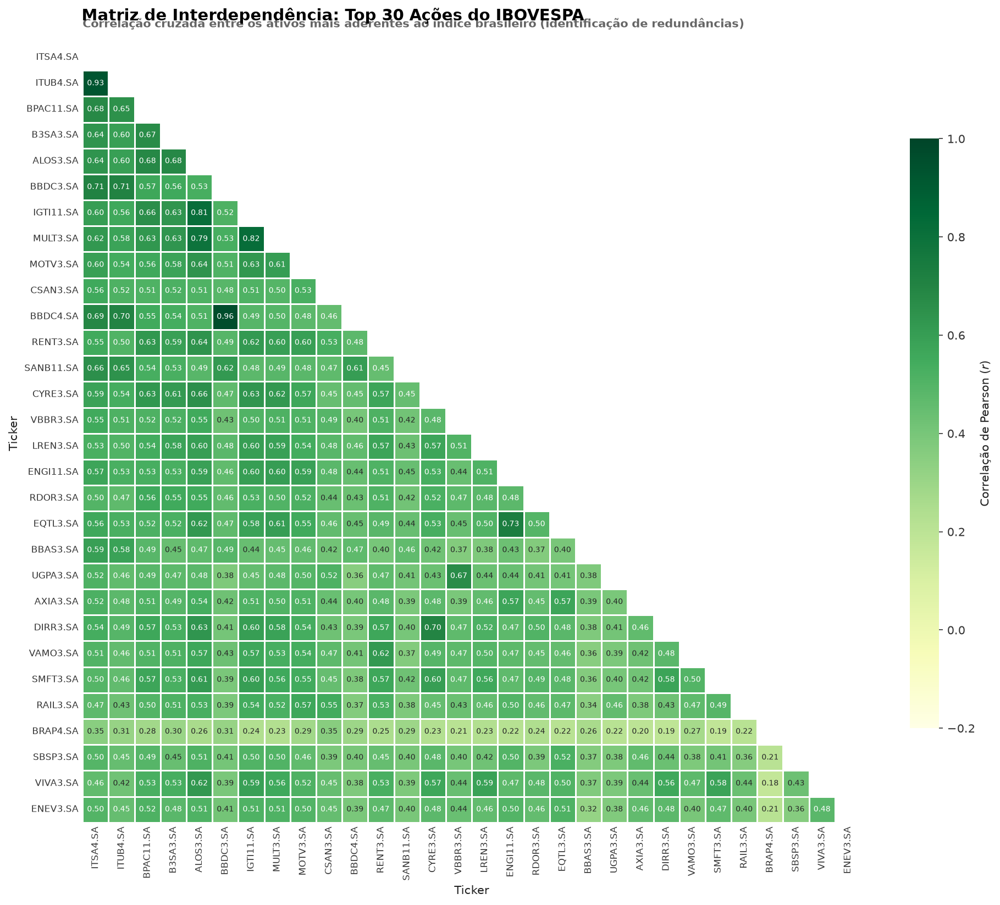

   PARES COM CORRELAÇÃO EXTREMA (> 0.90) — IBOVESPA
Total de pares altamente redundantes encontrados: 5

  Ação 1   Ação 2  Correlação
BBDC3.SA BBDC4.SA       0.964
PETR3.SA PETR4.SA       0.962
GGBR4.SA GOAU4.SA       0.957
ITSA4.SA ITUB4.SA       0.926
BRAP4.SA VALE3.SA       0.909


In [22]:
# ==============================================================================
# MATRIZ DE CORRELAÇÃO TOP 30 IBOVESPA (ESTILO NYT)
# ==============================================================================
set_nyt_style()

# 1. Matriz de correlação geral e seleção das 30 principais ações
corr_matrix_ib = ret_ibov_clean.corr()
top30_ib = corr_com_idx_ib.head(30).index
corr_top30_ib = ret_ibov_clean[top30_ib].corr()

# 2. Criar figura no padrão Orientado a Objetos
fig, ax = plt.subplots(figsize=(13, 11), dpi=150)

# 3. Criar máscara para o triângulo superior (exibe apenas o triângulo inferior)
mask_ib = np.triu(np.ones_like(corr_top30_ib, dtype=bool))

# 4. Plotar Heatmap no padrão verde/editorial do IBOVESPA
sns.heatmap(
    corr_top30_ib,
    mask=mask_ib,
    annot=True, 
    fmt='.2f',
    cmap='YlGn',           # Paleta verde sutil e elegante para a identidade do IBOV
    center=0.4, 
    square=True,
    linewidths=0.5,
    linecolor='#FFFFFF',   # Linhas separadoras brancas limpas
    vmin=-0.2, vmax=1,     # Escala ajustada para focar na variação real de correlações de ações
    cbar_kws={
        'shrink': 0.75, 
        'label': 'Correlação de Pearson ($r$)',
        'orientation': 'vertical'
    },
    annot_kws={'size': 6.5, 'weight': 'normal'},
    ax=ax
)

# 5. Ajuste nos eixos para eliminar poluição de bordas
ax.tick_params(axis='both', which='both', length=0, labelsize=8)
plt.xticks(rotation=90)
plt.yticks(rotation=0)

# 6. Títulos no estilo editorial NYT
plt.suptitle(
    'Matriz de Interdependência: Top 30 Ações do IBOVESPA', 
    x=0.08, y=0.98, fontweight='bold', fontsize=14, ha='left'
)
ax.set_title(
    'Correlação cruzada entre os ativos mais aderentes ao índice brasileiro (identificação de redundâncias)', 
    fontsize=10, color='#666666', pad=15, loc='left'
)

plt.tight_layout()
#plt.savefig('matriz_correlacao_ibovespa.png', dpi=300, bbox_inches='tight')
plt.show()

# ==============================================================================
# BUSCA DE PARES DE ALTA CORRELAÇÃO (REDUNDÂNCIA PARA O SOLVER)
# ==============================================================================
pares_alta_corr_ib = []
for i in range(len(corr_matrix_ib.columns)):
    for j in range(i + 1, len(corr_matrix_ib.columns)):
        r = corr_matrix_ib.iloc[i, j]
        if r > 0.90:
            pares_alta_corr_ib.append({
                'Ação 1': corr_matrix_ib.columns[i],
                'Ação 2': corr_matrix_ib.columns[j],
                'Correlação': round(r, 3)
            })

df_pares_ib = pd.DataFrame(pares_alta_corr_ib).sort_values('Correlação', ascending=False)

print("=" * 60)
print("   PARES COM CORRELAÇÃO EXTREMA (> 0.90) — IBOVESPA")
print("=" * 60)
print(f"Total de pares altamente redundantes encontrados: {len(df_pares_ib)}\n")
if len(df_pares_ib) > 0:
    print(df_pares_ib.head(20).to_string(index=False))
print("=" * 60)

In [23]:
# Cálculo do Beta em relação ao S&P 100
def calcular_metricas_replicacao(ret_acoes, ret_indice):
    col_idx = ret_indice.columns[0]
    var_indice = ret_indice[col_idx].var()
    
    metricas = []
    
    for col in ret_acoes.columns:
        r = ret_acoes[col].corr(ret_indice[col_idx])
        cov = ret_acoes[col].cov(ret_indice[col_idx])
        beta = cov / var_indice
        vol_acao = ret_acoes[col].std() * np.sqrt(252) # Volatilidade anualizada
        
        # Tracking error individual em relação ao índice
        te_individual = (ret_acoes[col] - ret_indice[col_idx]).std() * np.sqrt(252)
        
        metricas.append({
            'Ativo': col,
            'Pearson r': r,
            'Beta (β)': beta,
            'Volatilidade Anual': vol_acao,
            'Tracking Error Ind.': te_individual
        })
        
    df_metricas = pd.DataFrame(metricas).sort_values(by='Pearson r', ascending=False)
    return df_metricas

# Execução no S&P 100
df_analise_sp100 = calcular_metricas_replicacao(ret_sp100, ret_idx_sp)
df_analise_ibov = calcular_metricas_replicacao(ret_ibov, ret_idx_ib)

# Comparar com as Top 5 mais correlacionadas
print(df_analise_sp100.head(10).to_string(index=False, formatters={
    'Pearson r': '{:.4f}'.format,
    'Beta (β)': '{:.2f}'.format,
    'Volatilidade Anual': '{:.2%}'.format,
    'Tracking Error Ind.': '{:.2%}'.format
}))

print(df_analise_ibov.head(10).to_string(index=False, formatters={
    'Pearson r': '{:.4f}'.format,
    'Beta (β)': '{:.2f}'.format,
    'Volatilidade Anual': '{:.2%}'.format,
    'Tracking Error Ind.': '{:.2%}'.format
}))

Ativo Pearson r Beta (β) Volatilidade Anual Tracking Error Ind.
 NVDA    0.7484     2.12             51.32%              39.65%
 AMZN    0.7423     1.51             36.88%              26.41%
 AAPL    0.7420     1.16             28.15%              19.08%
 MSFT    0.7302     1.14             28.34%              19.54%
  BLK    0.7175     1.08             27.26%              19.04%
 GOOG    0.7062     1.27             32.38%              23.42%
GOOGL    0.7046     1.27             32.53%              23.59%
 LRCX    0.6674     1.86             50.35%              40.58%
   MS    0.6656     1.07             29.00%              21.68%
   GS    0.6613     1.05             28.81%              21.63%
    Ativo Pearson r Beta (β) Volatilidade Anual Tracking Error Ind.
 ITSA4.SA    0.7880     1.01             21.93%              13.50%
 ITUB4.SA    0.7400     0.99             22.97%              15.45%
BPAC11.SA    0.7276     1.45             33.96%              24.51%
 B3SA3.SA    0.7166     

In [24]:
def plotar_boxplot_correlacao_setorial(ret_acoes, ret_indice, path_csv_setores, col_ticker, col_setor, nome_indice):
    """
    Carrega o mapeamento setorial, calcula a correlação de Pearson por ativo,
    agrupa por setor e plota o Boxplot ordenado pela mediana no estilo NYT.
    """
    # 1. Aplica o estilo visual do projeto
    set_nyt_style()
    
    col_idx = ret_indice.columns[0] if isinstance(ret_indice, pd.DataFrame) else ret_indice.name
    s_indice = ret_indice[col_idx] if isinstance(ret_indice, pd.DataFrame) else ret_indice
    
    # 2. Carregar mapeamento setorial do CSV
    df_setores = pd.read_csv(path_csv_setores)
    df_setores[col_ticker] = df_setores[col_ticker].astype(str).str.strip()
    
    # 3. Calcular correlação de Pearson de cada ação com o benchmark
    correlacoes = ret_acoes.apply(lambda col: col.corr(s_indice))
    df_corr = pd.DataFrame({
        col_ticker: correlacoes.index,
        'Pearson_R': correlacoes.values
    })
    
    # Limpeza/Padronização dos Tickers para garantir o MERGE perfeito
    # Remove sufixos como .SA e caracteres especiais de ambos os lados para comparação
    df_corr['ticker_clean'] = df_corr[col_ticker].astype(str).str.replace('.SA', '', regex=False).str.replace('-', '.', regex=False).str.strip()
    df_setores['ticker_clean'] = df_setores[col_ticker].astype(str).str.replace('.SA', '', regex=False).str.replace('-', '.', regex=False).str.strip()
    
    # Realiza o Merge com base na coluna limpa
    df_merged = pd.merge(df_corr, df_setores[[col_setor, 'ticker_clean']], on='ticker_clean', how='inner')
    
    if df_merged.empty:
        print(f"⚠️ ERRO: Nenhuma ação do {nome_indice} coincidiu entre os retornos e o arquivo CSV de setores.")
        print(f"Exemplo de tickers nos retornos: {df_corr[col_ticker].head(3).tolist()}")
        print(f"Exemplo de tickers no CSV: {df_setores[col_ticker].head(3).tolist()}")
        return None, None

    print(f"✅ Total de ações mapeadas no {nome_indice}: {len(df_merged)} de {ret_acoes.shape[1]}")
    
    # 4. Ordenar setores pela MEDIANA da correlação (do maior para o menor)
    ordem_setores = (
        df_merged.groupby(col_setor)['Pearson_R']
        .median()
        .sort_values(ascending=False)
        .index
    )
    
    # 5. Seleção Dinâmica da Paleta e Cores por Índice
    is_ibov = 'IBOV' in nome_indice.upper()
    cor_principal = '#1B4D3E' if is_ibov else '#2B6999'
    palette_name = 'Greens_r' if is_ibov else 'Blues_r'
    
    # Gera as cores exatamente na quantidade de setores e na ordem correta
    num_setores = len(ordem_setores)
    cores_ordenadas = sns.color_palette(palette_name, n_colors=num_setores)
    
    # 6. Construção do Gráfico (Orientado a Objetos)
    fig, ax = plt.subplots(figsize=(14, 7), dpi=150)
    
    # Boxplot minimalista com ordenação estrita de cores
    sns.boxplot(
        data=df_merged,
        x=col_setor,
        y='Pearson_R',
        order=ordem_setores,
        hue=col_setor,
        hue_order=ordem_setores,   # Garante que as cores sigam a ordem da mediana
        palette=cores_ordenadas,   # Aplica a lista de cores gerada
        legend=False,
        ax=ax,
        fliersize=0,
        boxprops=dict(alpha=0.65, edgecolor='#333333', linewidth=0.8),
        medianprops=dict(color='#C53030', linewidth=1.8),
        whiskerprops=dict(color='#333333', linewidth=0.8),
        capprops=dict(color='#333333', linewidth=0.8)
    )
    
    # Sobreposição de pontos (Stripplot)
    sns.stripplot(
        data=df_merged,
        x=col_setor,
        y='Pearson_R',
        order=ordem_setores,
        color='#2D3748',
        alpha=0.6,
        jitter=0.2,
        size=4.5,
        ax=ax
    )
    
    # 7. Linhas de Referência Horizontais
    ax.axhline(y=0.70, color=cor_principal, linestyle='--', linewidth=1.2, alpha=0.85, zorder=3)
    ax.axhline(y=0.50, color='#C53030', linestyle='--', linewidth=1.2, alpha=0.85, zorder=3)
    
    # Anotações Diretas nas Linhas
    ax.text(num_setores - 0.5, 0.71, 'Forte ( > 0.70 )', color=cor_principal, fontweight='bold', fontsize=9, ha='right', va='bottom')
    ax.text(num_setores - 0.4, 0.51, ' / Baixa ( < 0.50 )', color='#C53030', fontweight='bold', fontsize=9, ha='right', va='bottom')
    ax.text(num_setores - 1.25, 0.51, 'Moderada', color='#4A5568', fontweight='bold', fontsize=9, ha='right', va='bottom')
    
    # 8. Eixos, Rotação sem Warning e Grid
    y_min = min(-0.05, df_merged['Pearson_R'].min() - 0.05)
    ax.set_ylim(y_min, 1.05)
    ax.set_ylabel('Correlação de Pearson ($r$)', fontsize=11, labelpad=8)
    ax.set_xlabel('', fontsize=11)
    
    # Correção do aviso (UserWarning): rotação limpa dos rótulos
    ax.tick_params(axis='x', rotation=35, labelsize=9.5)
    plt.xticks(ha='right')
    
    ax.grid(axis='y', color='#E5E5E5', linestyle='--', alpha=0.7)
    ax.grid(axis='x', visible=False)
    
    # 9. Títulos no estilo NYT
    plt.suptitle(
        f'Aderência Setorial ao Benchmark: {nome_indice}', 
        x=0.08, y=0.99, fontweight='bold', fontsize=14, ha='left'
    )
    ax.set_title(
        'Distribuição e mediana da correlação de Pearson dos ativos agrupados por setor econômico', 
        fontsize=10, color='#666666', pad=15, loc='left'
    )
    
    plt.tight_layout()
    #plt.savefig(f'boxplot_setorial_{nome_indice.lower().replace(" ", "_")}.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # 10. Tabela Resumo (Sintaxe dos Print Corrigida)
    resumo_setorial = df_merged.groupby(col_setor)['Pearson_R'].agg(
        Qtd_Ações='count',
        Mediana='median',
        Média='mean',
        Desvio_Padrão='std'
    ).loc[ordem_setores].reset_index()
    
    print("=" * 65)
    print(f"      RESUMO DE ADERÊNCIA SETORIAL AO {nome_indice}")
    print("=" * 65)
    print(resumo_setorial.to_string(index=False, formatters={
        'Mediana': '{:.4f}'.format,
        'Média': '{:.4f}'.format,
        'Desvio_Padrão': '{:.4f}'.format
    }))
    print("=" * 65 + "\n")
    
    return df_merged, resumo_setorial

✅ Total de ações mapeadas no ^OEX: 99 de 99


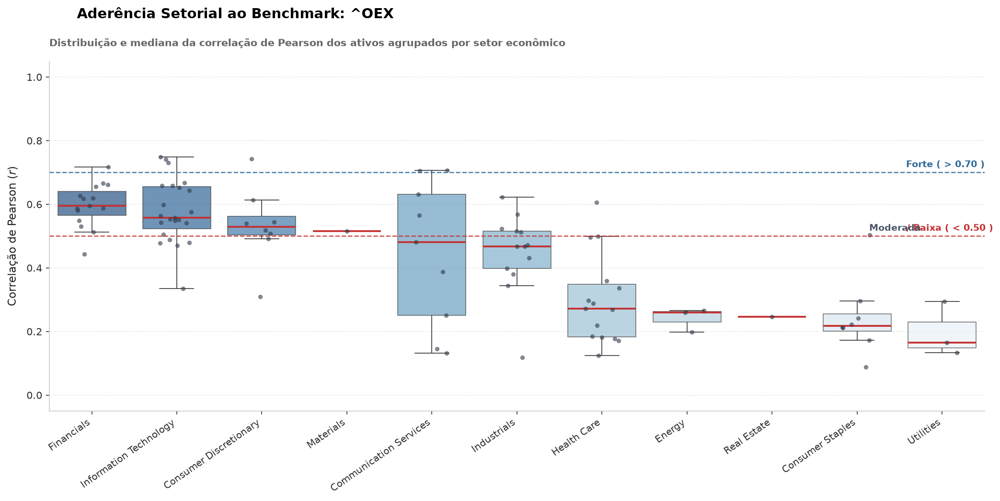

      RESUMO DE ADERÊNCIA SETORIAL AO ^OEX
                Sector  Qtd_Ações Mediana  Média Desvio_Padrão
            Financials         15  0.5946 0.5965        0.0689
Information Technology         23  0.5583 0.5780        0.0997
Consumer Discretionary          8  0.5288 0.5334        0.1213
             Materials          1  0.5156 0.5156           NaN
Communication Services          9  0.4817 0.4450        0.2277
           Industrials         13  0.4680 0.4476        0.1248
           Health Care         15  0.2721 0.2988        0.1402
                Energy          3  0.2606 0.2414        0.0375
           Real Estate          1  0.2460 0.2460           NaN
      Consumer Staples          8  0.2181 0.2437        0.1204
             Utilities          3  0.1645 0.1974        0.0859

✅ Total de ações mapeadas no IBOVESPA: 75 de 75


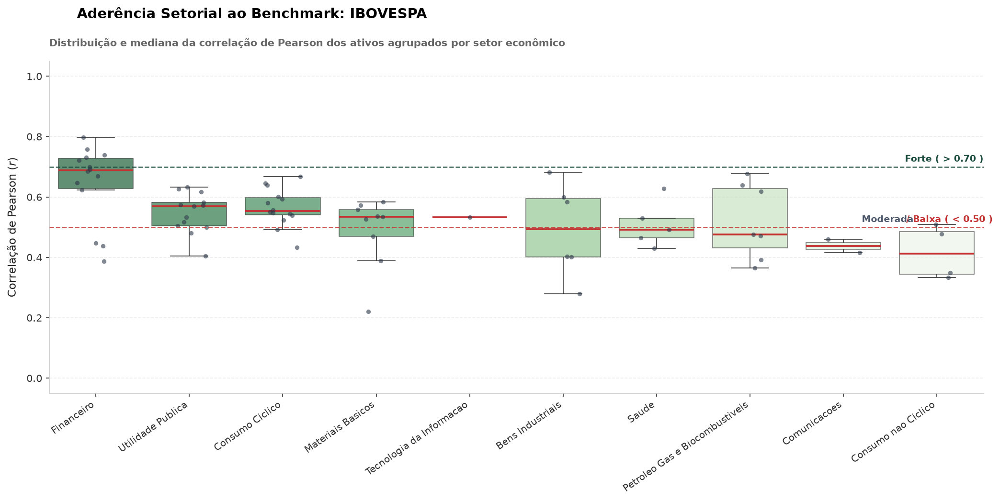

      RESUMO DE ADERÊNCIA SETORIAL AO IBOVESPA
                         Setor  Qtd_Ações Mediana  Média Desvio_Padrão
                    Financeiro         14  0.6886 0.6454        0.1285
             Utilidade Publica         13  0.5701 0.5474        0.0657
               Consumo Ciclico         14  0.5538 0.5652        0.0626
             Materiais Basicos          9  0.5350 0.4880        0.1166
      Tecnologia da Informacao          1  0.5334 0.5334           NaN
              Bens Industriais          6  0.4932 0.4914        0.1532
                         Saude          5  0.4916 0.5087        0.0763
Petroleo Gas e Biocombustiveis          7  0.4758 0.5199        0.1248
                  Comunicacoes          2  0.4378 0.4378        0.0309
           Consumo nao Ciclico          4  0.4132 0.4169        0.0893



In [25]:
df_setores_sp100, resumo_sp100 = plotar_boxplot_correlacao_setorial(
    ret_acoes=ret_sp100_clean,
    ret_indice=ret_idx_sp,
    path_csv_setores='SP100_wikipedia_21set2026.csv',
    col_ticker='Symbol',
    col_setor='Sector',
    nome_indice='^OEX'
)


df_setores_ibov, resumo_ibov = plotar_boxplot_correlacao_setorial(
    ret_acoes=ret_ibov_clean,
    ret_indice=ret_idx_ib,
    path_csv_setores='IBOVESPA_B3_24set2026.csv',
    col_ticker='Codigo',
    col_setor='Setor',
    nome_indice='IBOVESPA'
)

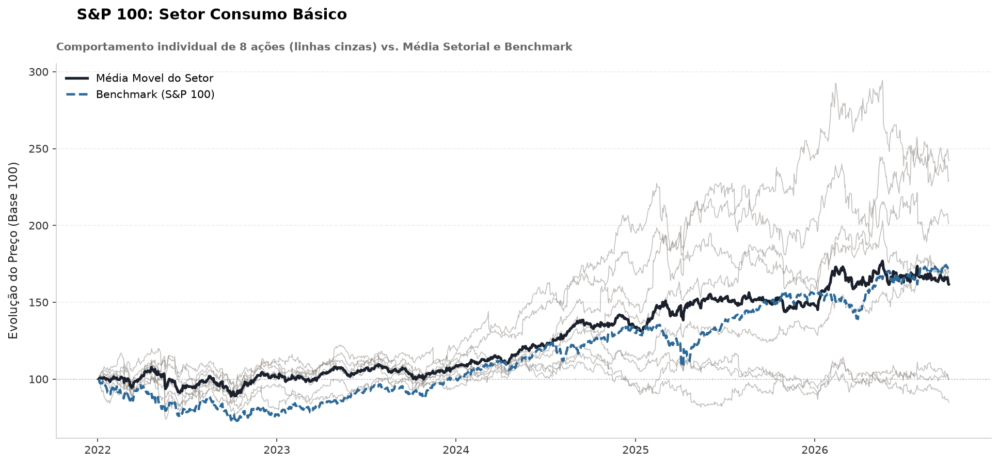

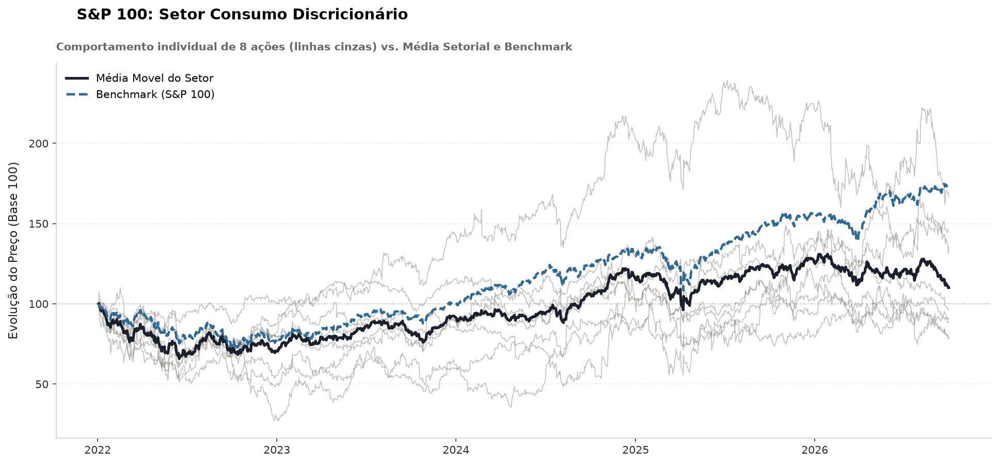

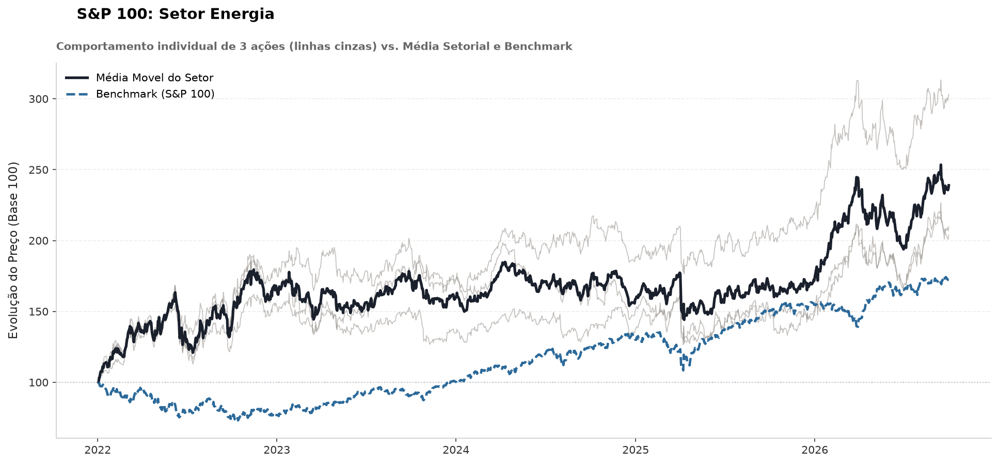

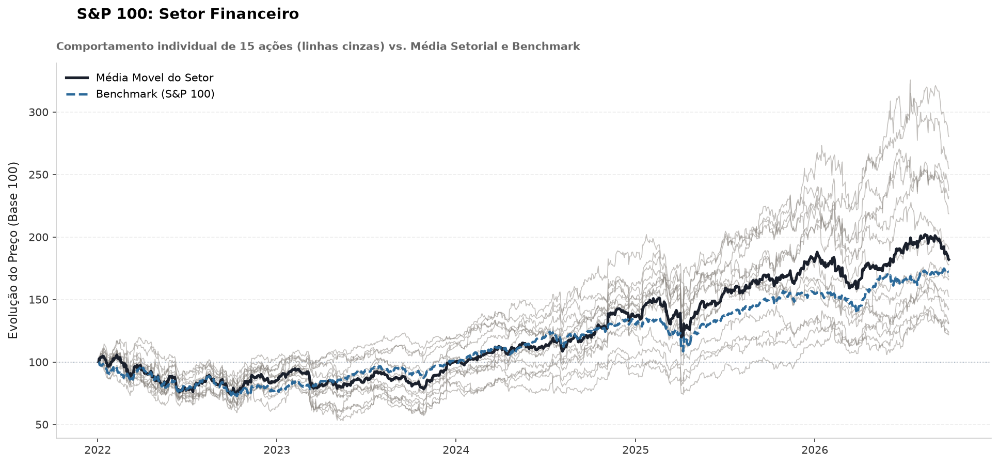

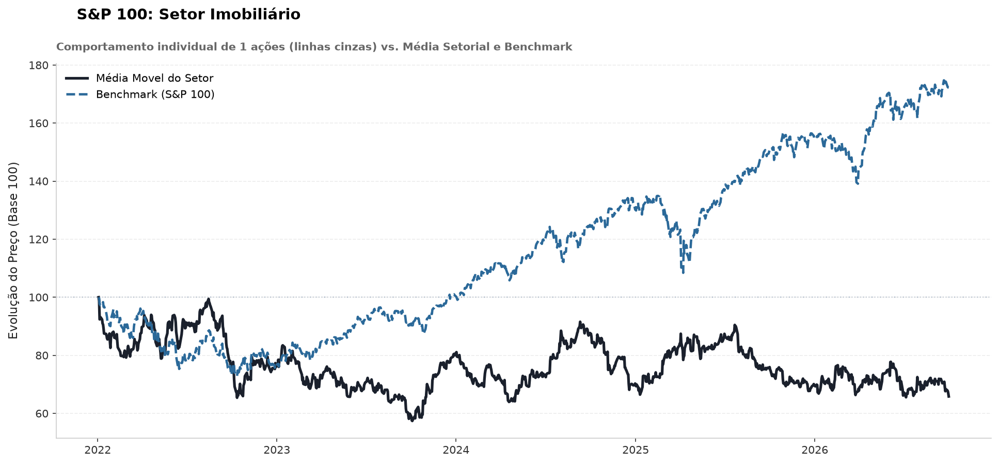

...

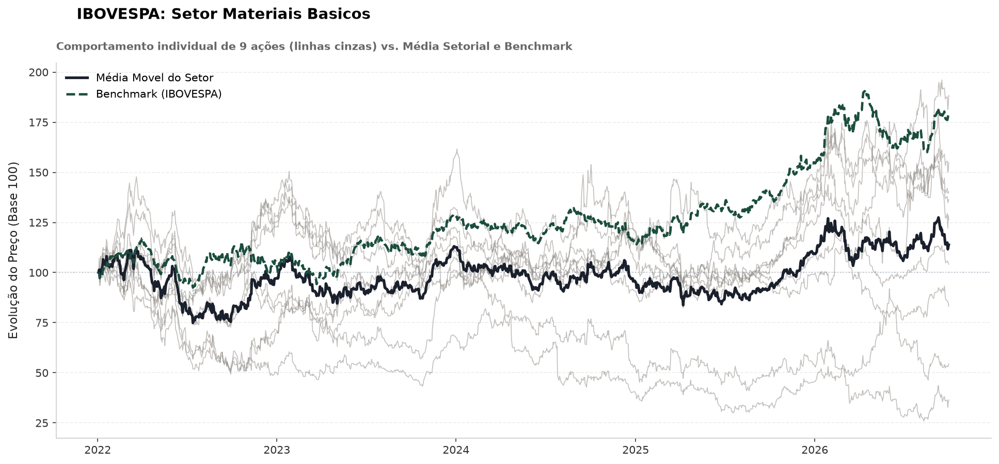

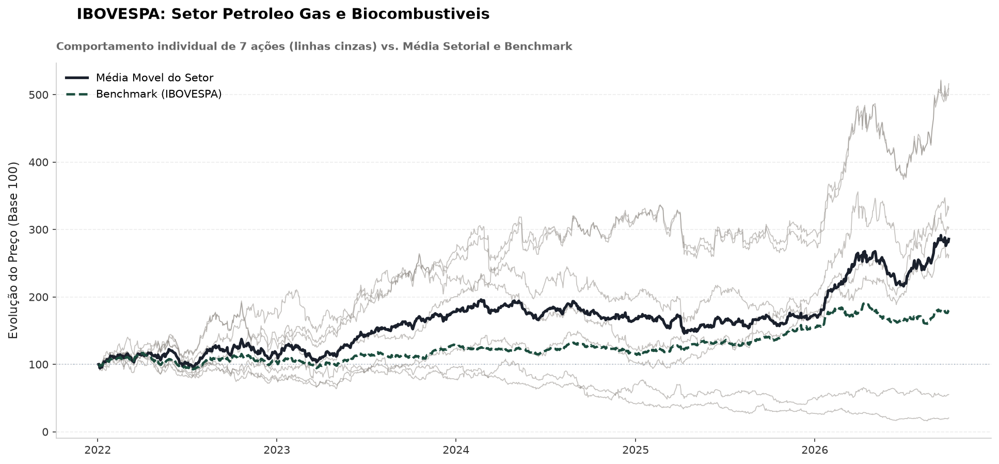

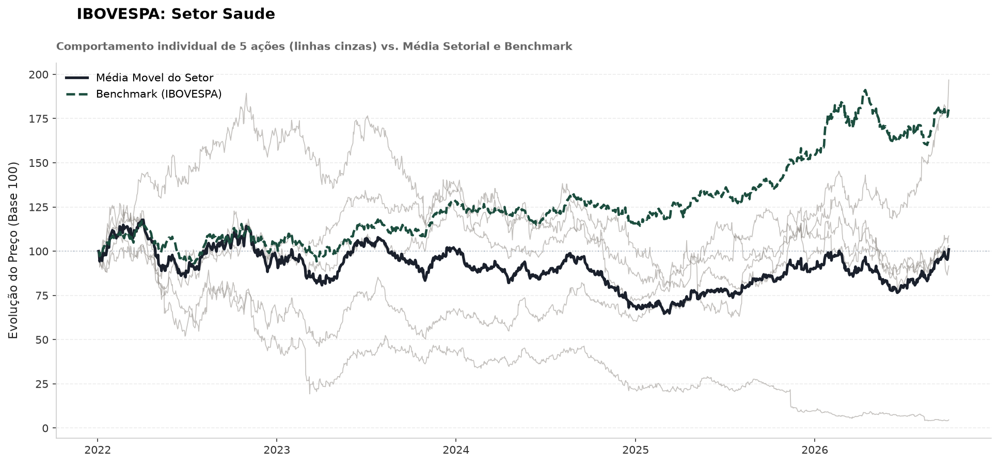

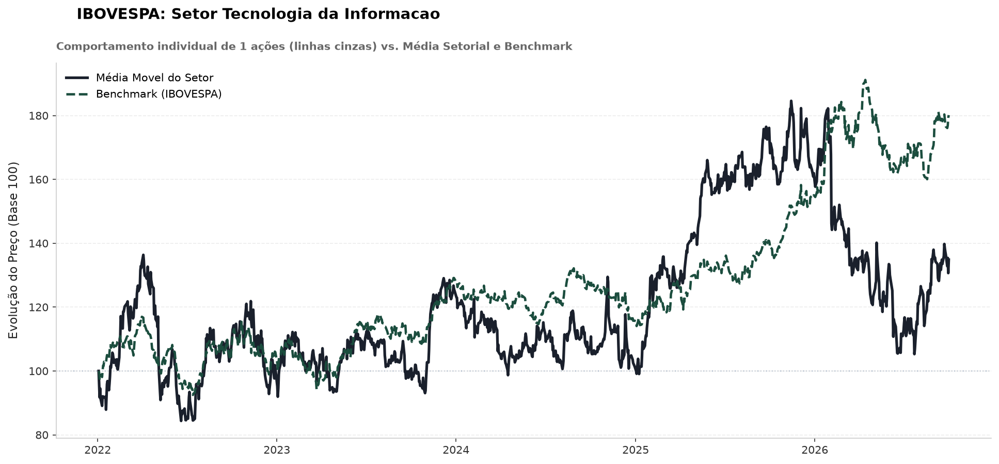

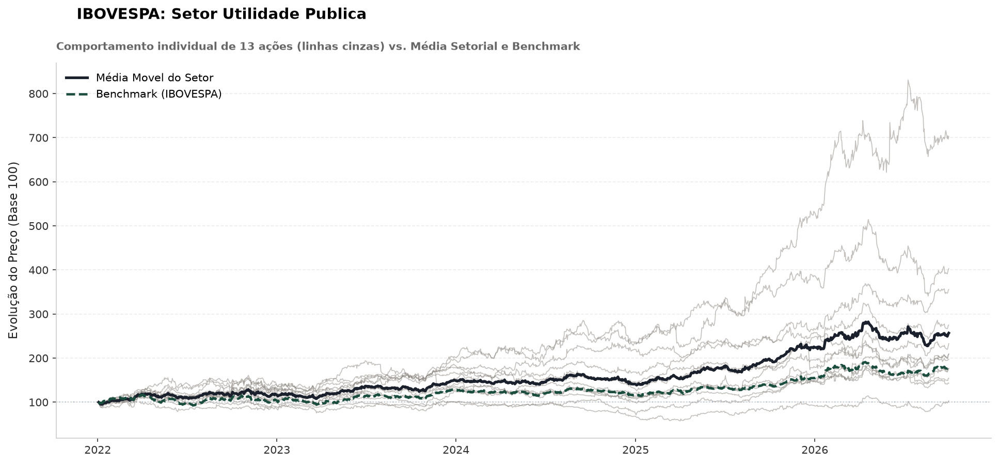

In [26]:
# Tradução dos setores do S&P 100
traducao_sp100 = {
    'Information Technology': 'Tecnologia da Informação', 
    'Health Care': 'Saúde',
    'Financials': 'Financeiro', 
    'Industrials': 'Industrial',
    'Communication Services': 'Serviços de Comunicação', 
    'Consumer Discretionary': 'Consumo Discricionário',
    'Consumer Staples': 'Consumo Básico', 
    'Energy': 'Energia', 
    'Utilities': 'Utilidades Públicas',
    'Real Estate': 'Imobiliário', 
    'Materials': 'Materiais'
}

# Dicionários de mapeamento Ticker -> Setor
setor_sp100 = dict(zip(SP100['Symbol'], SP100['Sector'].map(traducao_sp100)))
setor_ibov = dict(zip(IBOVESPA['Codigo'] + '.SA', IBOVESPA['Setor']))

def graficos_por_setor(dados_clean, indice, mapa_setores, nome_mercado, escala_log=False):
    """
    Gera 1 gráfico por setor (performance normalizada, Base 100) no estilo editorial NYT:
    - Cada ação do setor (linhas finas cinza/grafite)
    - Média do setor (linha preta/grafite destacada)
    - Índice do mercado (Azul para SP100 / Verde para IBOV)
    """
    # 1. Garante a aplicação do estilo visual do projeto
    set_nyt_style()
    
    is_ibov = 'IBOV' in nome_mercado.upper()
    cor_indice = '#1B4D3E' if is_ibov else '#2B6999'

    # 2. Normalização base 100 (1º valor válido de cada ação)
    precos = dados_clean.ffill()
    norm = precos / precos.bfill().iloc[0] * 100

    # 3. Ticker → setor
    setores = pd.Series({t: mapa_setores.get(t) for t in norm.columns})
    sem_setor = setores[setores.isna()].index.tolist()
    if sem_setor:
        print(f'⚠️ {nome_mercado}: ações sem setor (ignoradas): {sem_setor}')
    setores = setores.dropna()

    # 4. Média de cada setor
    medias_setor = pd.DataFrame({
        s: norm[setores[setores == s].index].mean(axis=1)
        for s in sorted(setores.unique())
    })

    # 5. Índice do mercado normalizado em base 100
    if isinstance(indice, pd.DataFrame):
        indice = indice.iloc[:, 0]
    indice = indice.ffill()
    indice_norm = indice / indice.bfill().iloc[0] * 100

    # 6. Um gráfico por setor
    for setor in medias_setor.columns:
        tickers = setores[setores == setor].index
        
        fig, ax = plt.subplots(figsize=(13, 6), dpi=150)
        
        # Linha de referência da Base 100
        ax.axhline(100, color='#A0AEC0', linestyle=':', linewidth=1, zorder=1)
        
        # Linhas das ações individuais (tons cinza/grafite suaves ao fundo)
        for i, t in enumerate(tickers):
            label_acao = t.replace('.SA', '') if i < 15 else (t.replace('.SA', '') if i == 15 else None) # Evita poluir a legenda se houver muitas ações
            ax.plot(
                norm.index, norm[t], 
                color='#88837d', linewidth=0.8, alpha=0.5, 
                zorder=2
            )
            
        # Média do setor em destaque
        ax.plot(
            medias_setor.index, medias_setor[setor], 
            color='#1A202C', linewidth=2.5, 
            label=f'Média Movel do Setor', zorder=3
        )
        
        # Índice do mercado (Azul para S&P100 / Verde para IBOV)
        ax.plot(
            indice_norm.index, indice_norm, 
            color=cor_indice, linewidth=2.2, linestyle='--', 
            label=f'Benchmark ({nome_mercado})', zorder=4
        )

        if escala_log:
            ax.set_yscale('log')

        # Ajuste dos eixos
        ax.set_ylabel('Evolução do Preço (Base 100)', fontsize=11, labelpad=8)
        ax.set_xlabel('', fontsize=11)
        ax.grid(axis='y', color='#E5E5E5', linestyle='--', alpha=0.7)
        ax.grid(axis='x', visible=False)

        # Legenda limpa e sem moldura
        ax.legend(frameon=False, loc='upper left', fontsize=10)

        # Hierarquia de Títulos NYT
        plt.suptitle(
            f'{nome_mercado}: Setor {setor}', 
            x=0.08, y=0.99, fontweight='bold', fontsize=14, ha='left'
        )
        ax.set_title(
            f'Comportamento individual de {len(tickers)} ações (linhas cinzas) vs. Média Setorial e Benchmark', 
            fontsize=10, color='#666666', pad=12, loc='left'
        )

        plt.tight_layout()
        #plt.savefig(f'setor_{nome_mercado.lower()}_{setor.lower().replace(" ", "_")}.png', dpi=300, bbox_inches='tight')
        plt.show()

    return medias_setor

# ---------------------------------------------------------
# EXECUÇÃO DAS FUNÇÕES
# ---------------------------------------------------------
medias_setor_sp = graficos_por_setor(dados_sp100_clean, indice_sp100, setor_sp100, 'S&P 100')
medias_setor_ib = graficos_por_setor(dados_ibov_clean, indice_ibov, setor_ibov, 'IBOVESPA')

   TOP 3 AÇÕES MAIS ADERENTES POR SETOR (r >= 0.50) - S&P 100

📂 Setor: FINANCIALS (Mediana do Setor: r = 0.595)
   • BLK          | Correlação com o Índice: 0.7175
   • MS           | Correlação com o Índice: 0.6656
   • GS           | Correlação com o Índice: 0.6613

📂 Setor: INFORMATION TECHNOLOGY (Mediana do Setor: r = 0.558)
   • NVDA         | Correlação com o Índice: 0.7484
   • AAPL         | Correlação com o Índice: 0.7420
   • MSFT         | Correlação com o Índice: 0.7302

📂 Setor: CONSUMER DISCRETIONARY (Mediana do Setor: r = 0.529)
   • AMZN         | Correlação com o Índice: 0.7423
   • TSLA         | Correlação com o Índice: 0.6133
   • BKNG         | Correlação com o Índice: 0.5447

📂 Setor: MATERIALS (Mediana do Setor: r = 0.516)
   • LIN          | Correlação com o Índice: 0.5156

📂 Setor: COMMUNICATION SERVICES (Mediana do Setor: r = 0.482)
   • GOOG         | Correlação com o Índice: 0.7062
   • GOOGL        | Correlação com o Índice: 0.7046
   • META         | Corr

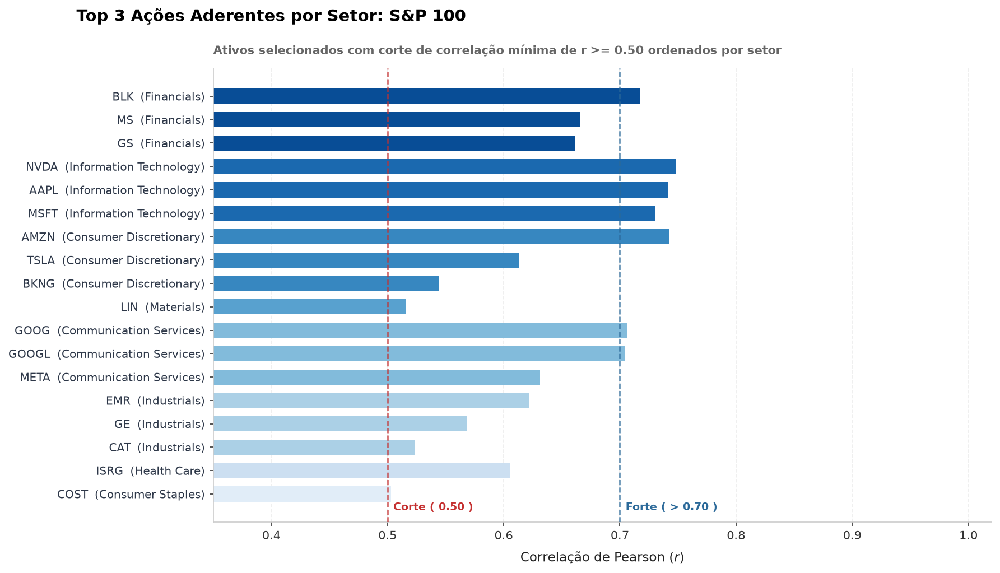

   TOP 3 AÇÕES MAIS ADERENTES POR SETOR (r >= 0.50) - IBOVESPA

📂 Setor: FINANCEIRO (Mediana do Setor: r = 0.689)
   • ITSA4.SA     | Correlação com o Índice: 0.7981
   • ITUB4.SA     | Correlação com o Índice: 0.7581
   • BPAC11.SA    | Correlação com o Índice: 0.7389

📂 Setor: UTILIDADE PUBLICA (Mediana do Setor: r = 0.570)
   • ENGI11.SA    | Correlação com o Índice: 0.6329
   • EQTL3.SA     | Correlação com o Índice: 0.6259
   • AXIA3.SA     | Correlação com o Índice: 0.6177

📂 Setor: CONSUMO CICLICO (Mediana do Setor: r = 0.554)
   • RENT3.SA     | Correlação com o Índice: 0.6676
   • CYRE3.SA     | Correlação com o Índice: 0.6455
   • LREN3.SA     | Correlação com o Índice: 0.6390

📂 Setor: MATERIAIS BASICOS (Mediana do Setor: r = 0.535)
   • BRAP4.SA     | Correlação com o Índice: 0.5836
   • CSNA3.SA     | Correlação com o Índice: 0.5726
   • GOAU4.SA     | Correlação com o Índice: 0.5589

📂 Setor: TECNOLOGIA DA INFORMACAO (Mediana do Setor: r = 0.533)
   • TOTS3.SA     | Corre

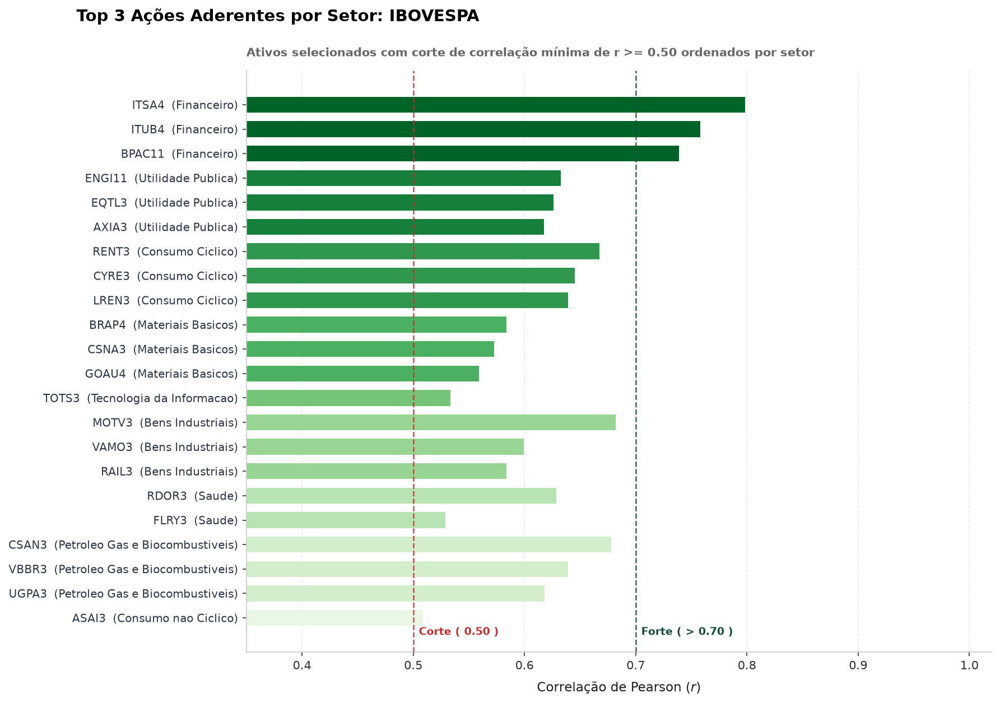

In [30]:
# ==============================================================================
# FUNÇÃO PRINCIPAL: IDENTIFICAR TOP AÇÕES POR SETOR (ESTILO NYT)
# ==============================================================================
def obter_top_acoes_por_setor(
    ret_acoes, 
    ret_indice, 
    mapa_setores, 
    col_ticker='Ticker', 
    col_setor='Setor', 
    corte_correlacao=0.50, 
    top_n=3,
    nome_indice='S&P 100'
):
    """
    Calcula a correlação de Pearson com o benchmark, filtra setores/ações
    com correlação acima do corte (ex: r > 0.50) e extrai o Top N de cada setor.
    Aplica o padrão gráfico editorial do New York Times.
    """
    # 1. Aplica o estilo gráfico do projeto
    set_nyt_style()

    # Garantir que a série do índice seja unidimensional (Series)
    s_idx = ret_indice.squeeze()
    if isinstance(s_idx, pd.DataFrame):
        s_idx = s_idx.iloc[:, 0]
        
    # Alinhamento temporal entre ações e benchmark
    datas_comuns = ret_acoes.index.intersection(s_idx.index)
    acoes_al = ret_acoes.loc[datas_comuns]
    idx_al = s_idx.loc[datas_comuns]

    # 2. Calcular a correlação de Pearson de cada ação com o índice
    corr_series = acoes_al.corrwith(idx_al)
    df_corr = pd.DataFrame({
        'Ticker': corr_series.index,
        'Correlacao': corr_series.values
    })

    # 3. Vincular os setores (via DataFrame/CSV ou Dicionário)
    if isinstance(mapa_setores, pd.DataFrame):
        df_set = mapa_setores[[col_ticker, col_setor]].copy()
        df_set.columns = ['Ticker', 'Setor']
        
        # Limpeza e padronização dos tickers
        df_corr['Ticker_Clean'] = df_corr['Ticker'].astype(str).str.replace('.SA', '', regex=False).str.replace('-', '.', regex=False).str.strip()
        df_set['Ticker_Clean'] = df_set['Ticker'].astype(str).str.replace('.SA', '', regex=False).str.replace('-', '.', regex=False).str.strip()
        
        df_dados = pd.merge(df_corr, df_set[['Setor', 'Ticker_Clean']], on='Ticker_Clean', how='left')
        df_dados = df_dados[['Ticker', 'Correlacao', 'Setor']]
            
    elif isinstance(mapa_setores, dict):
        df_dados = df_corr.copy()
        df_dados['Setor'] = df_dados['Ticker'].map(mapa_setores)
    else:
        raise ValueError("mapa_setores deve ser um DataFrame (CSV lido) ou um dict.")

    # Preencher setores não mapeados
    df_dados['Setor'] = df_dados['Setor'].fillna('Outros')

    # 4. Filtrar ações com correlação acima do corte (r >= corte_correlacao)
    df_filtrado = df_dados[df_dados['Correlacao'] >= corte_correlacao].copy()

    # 5. Classificar os setores pela mediana da correlação
    ranking_setores = (
        df_dados.groupby('Setor')['Correlacao']
        .median()
        .sort_values(ascending=False)
    )

    # 6. Selecionar o Top N ações de cada setor
    df_top_setorial = (
        df_filtrado.sort_values(['Setor', 'Correlacao'], ascending=[True, False])
        .groupby('Setor')
        .head(top_n)
        .reset_index(drop=True)
    )

    # Ordenar o resultado final pelos setores de maior correlação global
    df_top_setorial['Ordem_Setor'] = df_top_setorial['Setor'].map(
        {s: i for i, s in enumerate(ranking_setores.index)}
    )
    df_top_setorial = df_top_setorial.sort_values(['Ordem_Setor', 'Correlacao'], ascending=[True, False]).drop(columns=['Ordem_Setor'])

    # ==========================================================================
    # EXIBIÇÃO NO CONSOLE
    # ==========================================================================
    print("=" * 70)
    print(f"   TOP {top_n} AÇÕES MAIS ADERENTES POR SETOR (r >= {corte_correlacao:.2f}) - {nome_indice}")
    print("=" * 70)
    for setor, grupo in df_top_setorial.groupby('Setor', sort=False):
        mediana_setor = ranking_setores.get(setor, 0)
        print(f"\n📂 Setor: {setor.upper()} (Mediana do Setor: r = {mediana_setor:.3f})")
        for _, row in grupo.iterrows():
            print(f"   • {row['Ticker']:<12} | Correlação com o Índice: {row['Correlacao']:.4f}")
    print("=" * 70)

    # ==========================================================================
    # VISUALIZAÇÃO GRÁFICA (ESTILO EDITORIAL NYT)
    # ==========================================================================
    is_ibov = 'IBOV' in nome_indice.upper()
    cor_principal = '#1B4D3E' if is_ibov else '#2B6999'
    palette_name = 'Greens_r' if is_ibov else 'Blues_r'

    # Tamanho proporcional ao número de ações retornadas
    altura_fig = max(6, len(df_top_setorial) * 0.38)
    fig, ax = plt.subplots(figsize=(12, altura_fig), dpi=150)

    # Mapeamento de Cores Gradientes por Setor (Sóbrio e unificado)
    setores_unicos = df_top_setorial['Setor'].unique()
    paleta_setorial = sns.color_palette(palette_name, n_colors=len(setores_unicos))
    cor_map = dict(zip(setores_unicos, paleta_setorial))
    bar_colors = [cor_map[s] for s in df_top_setorial['Setor']]

    # Construção das Barras Horizontais
    y_pos = np.arange(len(df_top_setorial))
    ax.barh(y_pos, df_top_setorial['Correlacao'], color=bar_colors, edgecolor='none', height=0.65, zorder=2)

    # Rótulos no Eixo Y (Ação + Setor)
    labels = [f"{row['Ticker'].replace('.SA', '')}  ({row['Setor']})" for _, row in df_top_setorial.iterrows()]
    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels, fontsize=9.5, color='#2D3748')
    ax.invert_yaxis()  # O ativo de maior correlação no topo

    # Linhas Horizontais/Verticais de Referência
    ax.axvline(0.70, color=cor_principal, linestyle='--', linewidth=1.2, alpha=0.85, zorder=3)
    ax.axvline(corte_correlacao, color='#C53030', linestyle='--', linewidth=1.2, alpha=0.85, zorder=3)

    # Anotações Diretas nas Linhas (Substitui legenda tradicional)
    max_y = len(df_top_setorial) - 0.2
    ax.text(0.705, max_y, 'Forte ( > 0.70 )', color=cor_principal, fontweight='bold', fontsize=9, va='bottom')
    
    # Texto composto para o ponto de corte (0.50 ou dinâmico)
    ax.text(corte_correlacao + 0.005, max_y, f'Corte ( {corte_correlacao:.2f} )', color='#C53030', fontweight='bold', fontsize=9, va='bottom')

    # Ajuste de Eixos e Limites
    ax.set_xlim(min(0.35, corte_correlacao - 0.05), 1.02)
    ax.set_xlabel('Correlação de Pearson ($r$)', fontsize=11, labelpad=8)
    ax.set_ylabel('', fontsize=11)

    # Grid sutil apenas na vertical (Eixo X)
    ax.grid(axis='x', color='#E5E5E5', linestyle='--', alpha=0.7)
    ax.grid(axis='y', visible=False)

    # Hierarquia de Títulos NYT
    plt.suptitle(
        f'Top {top_n} Ações Aderentes por Setor: {nome_indice}', 
        x=0.08, y=0.99 if altura_fig <= 8 else 0.995, fontweight='bold', fontsize=14, ha='left'
    )
    ax.set_title(
        f'Ativos selecionados com corte de correlação mínima de r >= {corte_correlacao:.2f} ordenados por setor', 
        fontsize=10, color='#666666', pad=12, loc='left'
    )

    plt.tight_layout()
    #plt.savefig(f'top_acoes_setor_{nome_indice.lower().replace(" ", "_")}.png', dpi=300, bbox_inches='tight')
    plt.show()

    return df_top_setorial

    # 1. Execução S&P 100 (Gera o gráfico com tom Azul NYT)
df_setores_sp = pd.read_csv('SP100_wikipedia_21set2026.csv')

top_sp100 = obter_top_acoes_por_setor(
    ret_acoes=ret_sp100_clean,
    ret_indice=ret_idx_sp,
    mapa_setores=df_setores_sp,
    col_ticker='Symbol',
    col_setor='Sector',
    corte_correlacao=0.50,
    top_n=3,
    nome_indice='S&P 100'
)

# 2. Execução IBOVESPA (Gera o gráfico com tom Verde NYT)
df_setores_ibov = pd.read_csv('IBOVESPA_B3_24set2026.csv')

top_ibov = obter_top_acoes_por_setor(
    ret_acoes=ret_ibov_clean,
    ret_indice=ret_idx_ib,
    mapa_setores=df_setores_ibov,
    col_ticker='Codigo',
    col_setor='Setor',
    corte_correlacao=0.50,
    top_n=3,
    nome_indice='IBOVESPA'
)

# *Parte 2* - Modelo

In [31]:
# Divisão temporal
treino   = ret_sp100_clean.loc['2022-01-01':'2023-12-31']
valid    = ret_sp100_clean.loc['2024-01-01':'2025-12-31']
teste    = ret_sp100_clean.loc['2026-01-01':'2026-10-02']
idx_treino = ret_idx_sp.loc[treino.index]
idx_valid  = ret_idx_sp.loc[valid.index]
idx_teste  = ret_idx_sp.loc[teste.index]
print(f'Treino: {len(treino)} dias | Validação: {len(valid)} | Teste: {len(teste)}')

Treino: 500 dias | Validação: 502 | Teste: 188


In [36]:
def construir_features(ret_acoes, ret_indice, setores):
    """Tabela ação x feature, calculada apenas com os dados recebidos (treino)."""
    feats = pd.DataFrame(index=ret_acoes.columns)
    feats['corr_idx'] = ret_acoes.corrwith(ret_indice)
    feats['beta']     = ret_acoes.apply(lambda s: s.cov(ret_indice) / ret_indice.var())
    feats['vol_anual'] = ret_acoes.std() * np.sqrt(252)
    feats['setor']    = feats.index.map(setores).fillna('Outros')
    corr = ret_acoes.corr()
    feats['corr_media_pares'] = (corr.sum() - 1) / (len(corr) - 1)
    # TODO (grupo): adicionar peso no índice, drawdown, momentum etc.
    return feats
features_sp = construir_features(treino, idx_treino, setores_sp100)
print(features_sp.sort_values('corr_idx', ascending=False).head(10))

NameError: name 'setores_sp100' is not defined